# When a complex rule reverses its shorter parent

This automatic screen looks for opposite Control-to-Severe trends after adding cell-type context. A parent is a shorter rule the conditional test compared it with, measured in the same field; it keeps the arrow sides. Both rules use the complex rule's eligible FOVs, so changing denominators cannot create the reversal.

In [1]:
import os
import sys

sys.path[:0] = [os.path.abspath('scripts'), os.path.abspath('..'), os.path.abspath('../differential_rules/scripts')]
import complex_investigation as ci
import parent_trend_reversals as reversals
import parent_trend_reversals_vis as vis
from IPython.display import display

In [2]:
CONFIG = ci.Config(
    support=0.01, expected_support=0.01, confidence=0.5,
    score=os.environ.get('SCORE_COLUMN', 'Clinical score'),
)
MIN_ELIGIBLE, MIN_MILD_ELIGIBLE = 10, 8
MIN_PATIENTS, MIN_GAP, MIN_HITS, TOP_N = 3, .20, 5, 7

In [3]:
cells, metadata, rules = ci.load(CONFIG)
data = reversals.prepare(rules, cells, metadata, CONFIG)
print(f'{len(data["pairs"]):,} measured, role-preserving parent links screened')

Dropped 21 FOVs: Control_S
Loaded 598093 cells; FOVs: 267, biopsies: 73, patients: 71
Read results_CN_pairwise.csv + results_CN_complex.csv
{'max_items': 4, 'mining_fdr': 0.05, 'support': 0.01, 'confidence': 0.5, 'expected_support': 0.01, 'score': 'Clinical score', 'min_fovs': 5, 'min_patients': 3, 'min_group_fovs': 10, 'visible_gap': 0.15, 'attraction_lift_gap': 0.3, 'avoidance_lift_gap': 0.15, 'permutations': 4999, 'top_n': 8}
690,345 stored center-specific occurrences; distinct cell types only
Mining settings: {'settings': {'weighting': 'binary', 'method': 'CN', 'radius': 25.0, 'min_support': 0.01, 'min_lift': 1.2, 'max_items_per_rule': 4, 'bandwidth': 15.0, 'k_neighbors': None, 'min_cells_per_patch': 2, 'max_one_type_share': 0.9, 'min_patches': 15, 'strong_confidence': 0.9, 'min_support_when_strong': 0.005, 'min_confidence': 0.5, 'min_leverage': 0.0005, 'min_conviction': 1.3, 'include_avoidance_rules': True, 'avoidance_max_lift': 0.8, 'avoidance_max_leverage': None, 'avoidance_min_

In [4]:
selected = reversals.select(data, MIN_ELIGIBLE, MIN_PATIENTS, MIN_GAP, MIN_HITS,
                            TOP_N, MIN_MILD_ELIGIBLE)
display(selected)
selected.to_csv(ci.ROOT / 'summary_downloads' / 'parent_trend_reversals_selected.csv', index=False)

,organ,rule,parent,parent_gap,complex_gap,balanced_gap,matched_fovs,control_eligible,severe_eligible
0,Colon,Goblet + Macrophage -> CD8T + Plasma,Goblet + Macrophage -> Plasma,-0.476923,0.480000,0.476923,12,25,26
1,Duodenum,Muscle + SMV -> CD4T + Plasma,Muscle -> CD4T,-0.519231,0.384615,0.384615,10,13,20
2,Colon,Goblet + Macrophage -> CD4T + Plasma,Goblet + Macrophage -> Plasma,-0.443478,0.360000,0.360000,17,25,23
3,Colon,CD8T + Goblet -> Fibroblast + Plasma,CD8T -> Plasma,-0.400000,0.360000,0.360000,4,25,21
4,Duodenum,Fibroblast + Plasma -> Muscle,Plasma -> Muscle,0.357143,-0.363636,0.357143,8,14,22
5,Duodenum,Epithelial + Plasma -> Fibroblast + Goblet,Epithelial + Plasma -> Goblet,-0.369697,0.339394,0.339394,42,30,22
6,Duodenum,Fibroblast + Macrophage + Plasma -> Muscle,Plasma -> Muscle,0.357143,-0.337662,0.337662,9,14,22
7,Duodenum,Muscle + Neuron -> CD4T + Plasma,Muscle -> CD4T,-0.608059,0.336996,0.336996,10,13,21
8,Duodenum,CD4T + Fibroblast + Plasma -> Goblet,Fibroblast -> Goblet,-0.333333,0.366667,0.333333,46,30,20
9,Colon,CD4T + Epithelial + Macrophage -> Goblet,CD4T -> Goblet,0.325000,-0.630000,0.325000,15,25,40


The rank uses the smaller of the two opposite net changes, not a p-value. At least 10 common eligible FOVs are required at each endpoint and eight in Mild, plus at least three patients and five rule-bearing FOVs. These are exploratory, selected-on-effect comparisons—not independent significance tests. Net prevalence is an association-rule summary, not a causal direction.

In [5]:
def show_selected(index):
    vis.show_selected(index, selected, data, cells)

[0] Colon: Goblet + Macrophage -> Plasma  vs  Goblet + Macrophage -> CD8T + Plasma
FOVs testable for both rules; net = attraction share − avoidance share.


,stage,role,attraction,avoidance,eligible,patients,rule_patients,net
0,Control,parent,16,6,25,4,4,0.400000
1,Control,complex,4,16,25,4,4,-0.480000
2,Mild,parent,0,1,8,3,1,-0.125000
3,Mild,complex,0,0,8,3,0,0.000000
4,Severe,parent,2,4,26,10,4,-0.076923
5,Severe,complex,0,0,26,10,0,0.000000


saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_6be9f0b28f_summary.pdf


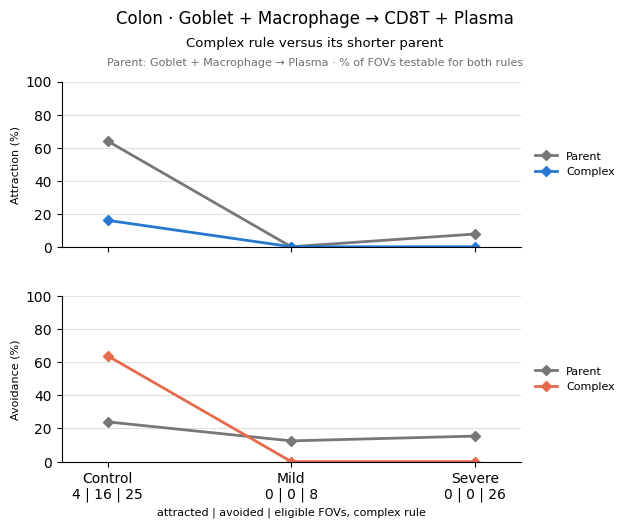

Read results_CN_pairwise.csv + results_CN_complex.csv
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_6be9f0b28f_parent_fovs_attraction.pdf


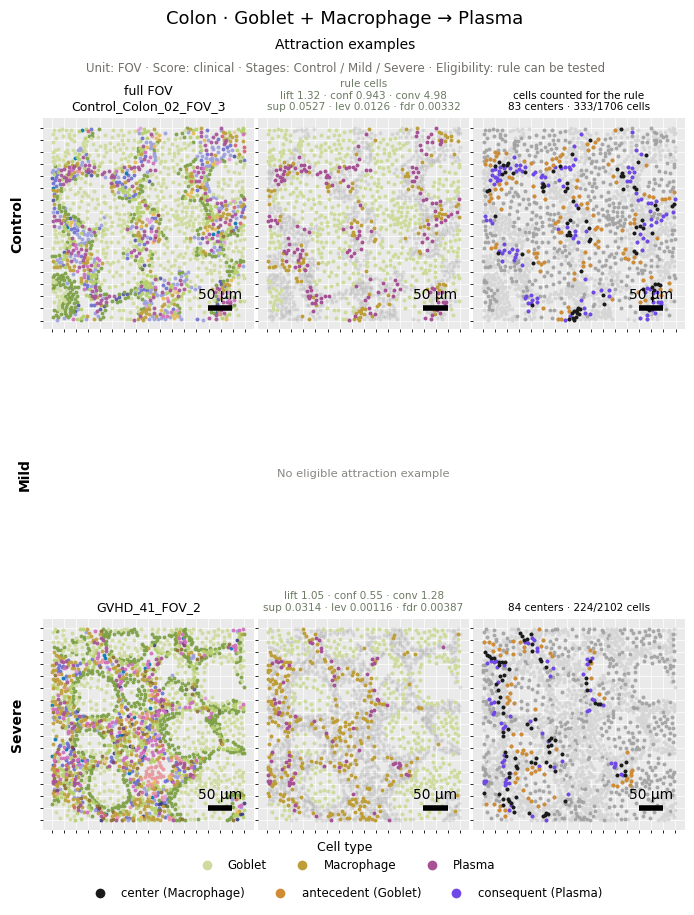

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_6be9f0b28f_parent_fovs_avoidance.pdf


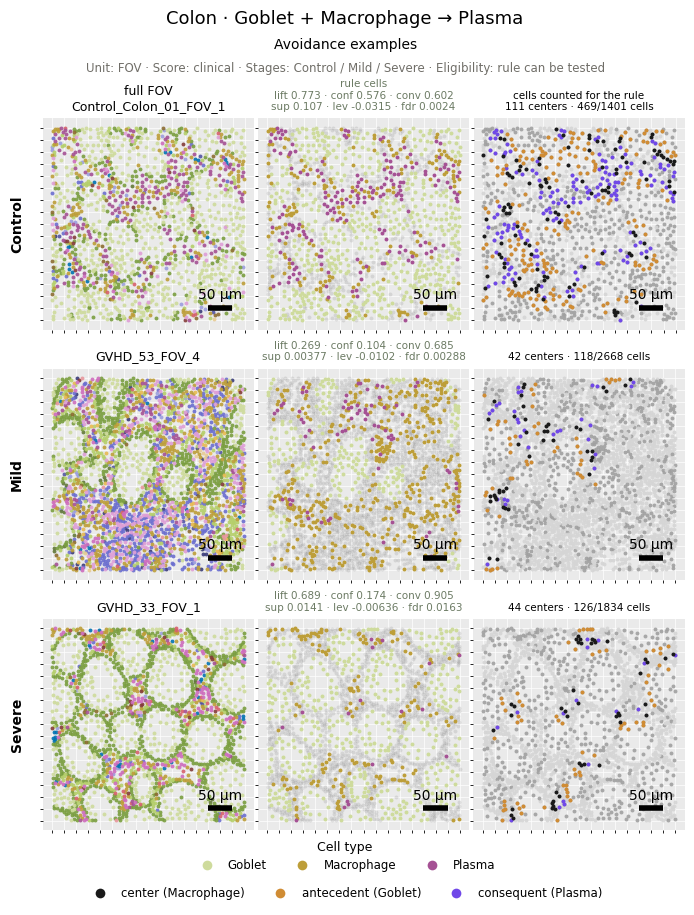

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_6be9f0b28f_parent_fovs_no_rule.pdf


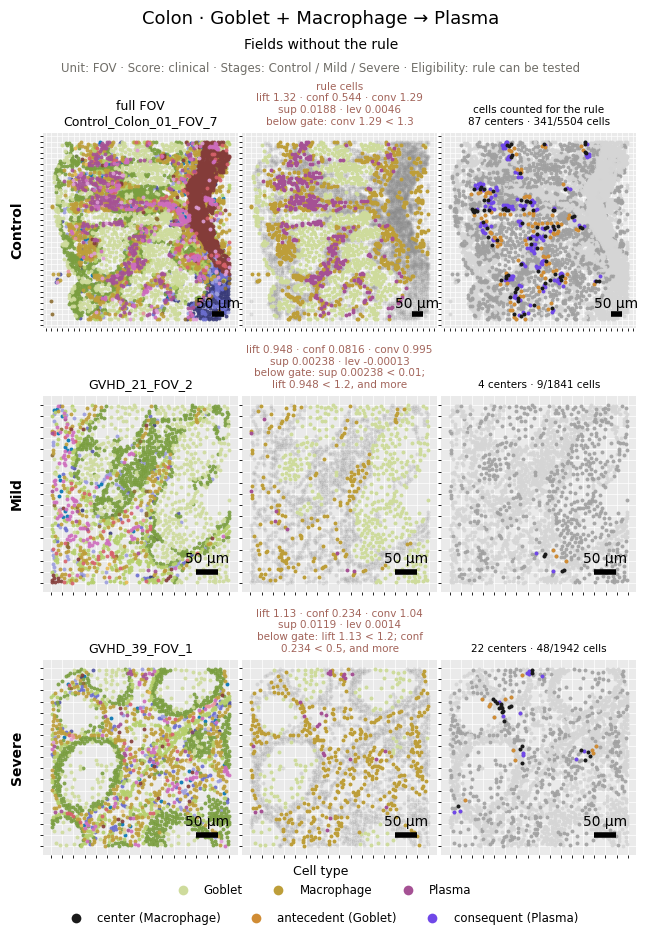

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_6be9f0b28f_complex_fovs_attraction.pdf


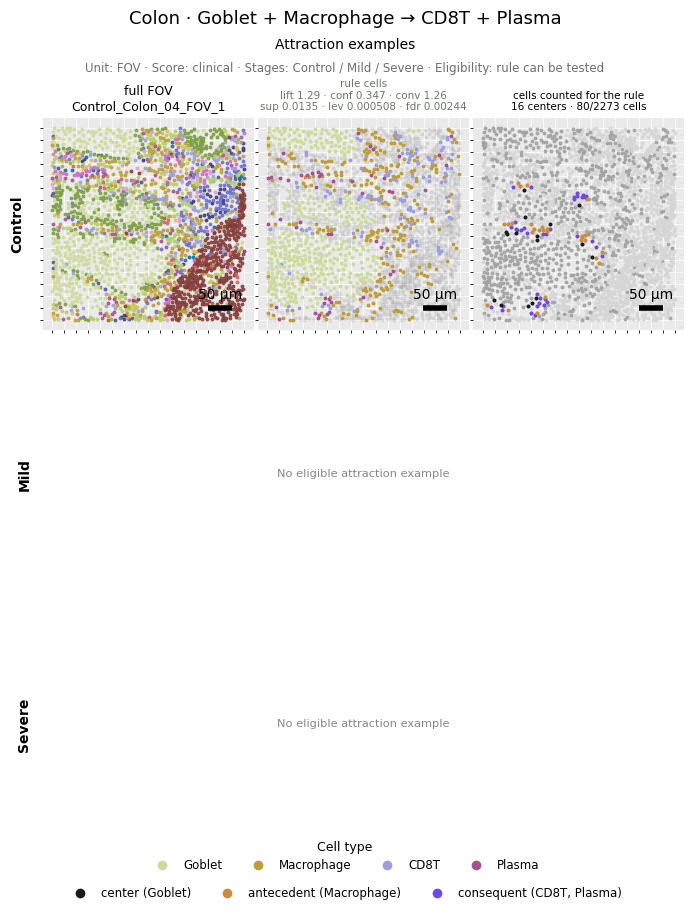

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_6be9f0b28f_complex_fovs_avoidance.pdf


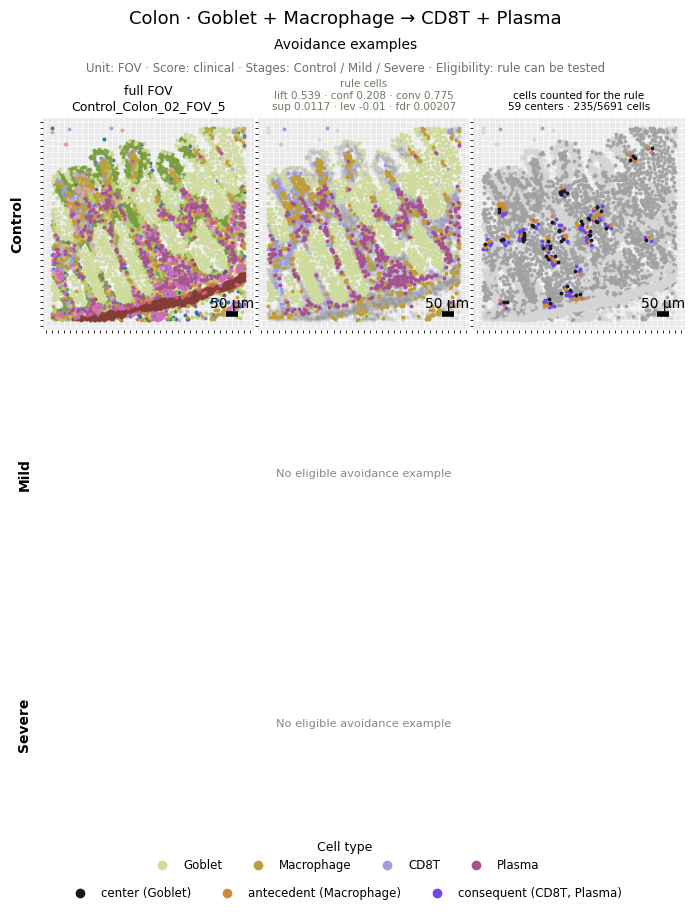

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_6be9f0b28f_complex_fovs_no_rule.pdf


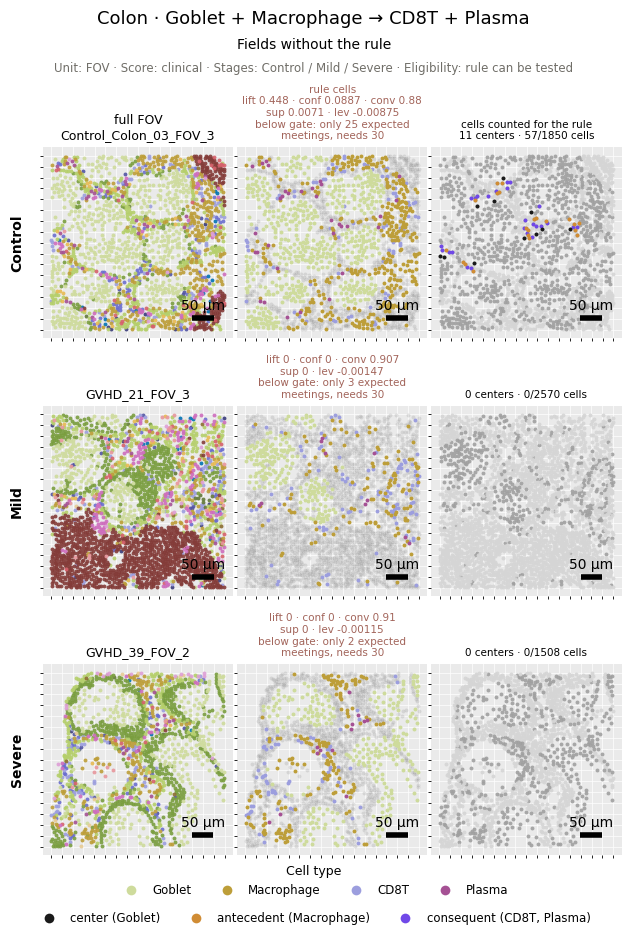

In [6]:
show_selected(0)

[1] Duodenum: Muscle -> CD4T  vs  Muscle + SMV -> CD4T + Plasma
FOVs testable for both rules; net = attraction share − avoidance share.


,stage,role,attraction,avoidance,eligible,patients,rule_patients,net
0,Control,parent,1,4,13,8,4,-0.230769
1,Control,complex,0,5,13,8,4,-0.384615
2,Mild,parent,1,28,50,22,18,-0.540000
3,Mild,complex,1,12,50,22,11,-0.220000
4,Severe,parent,0,15,20,8,7,-0.750000
5,Severe,complex,0,0,20,8,0,0.000000


saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_5a23eed2d4_summary.pdf


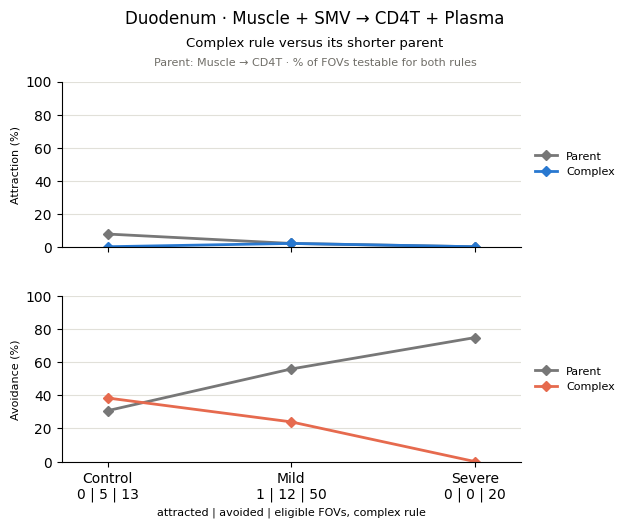

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_5a23eed2d4_parent_fovs_attraction.pdf


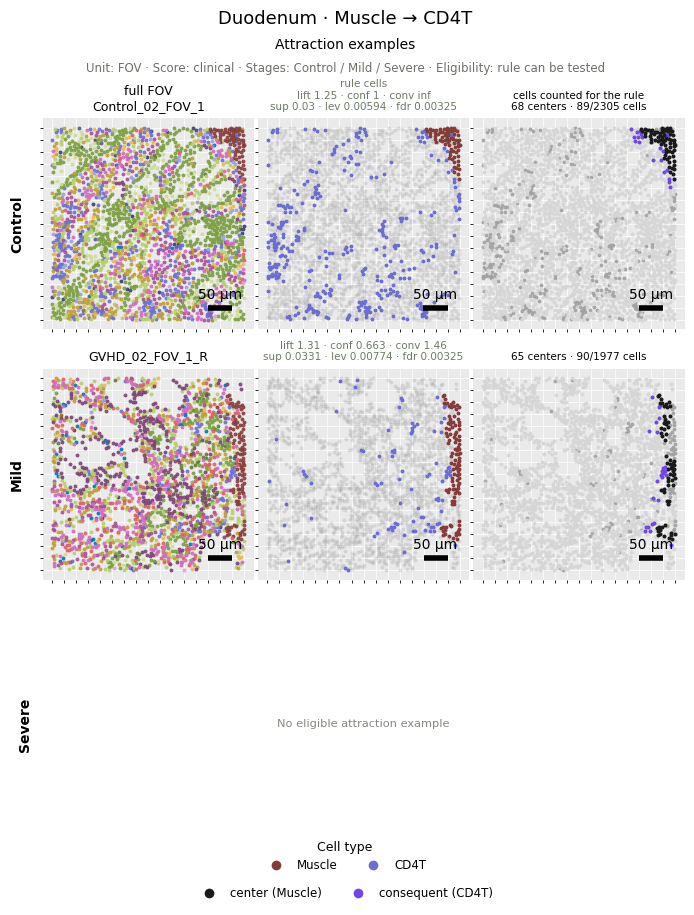

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_5a23eed2d4_parent_fovs_avoidance.pdf


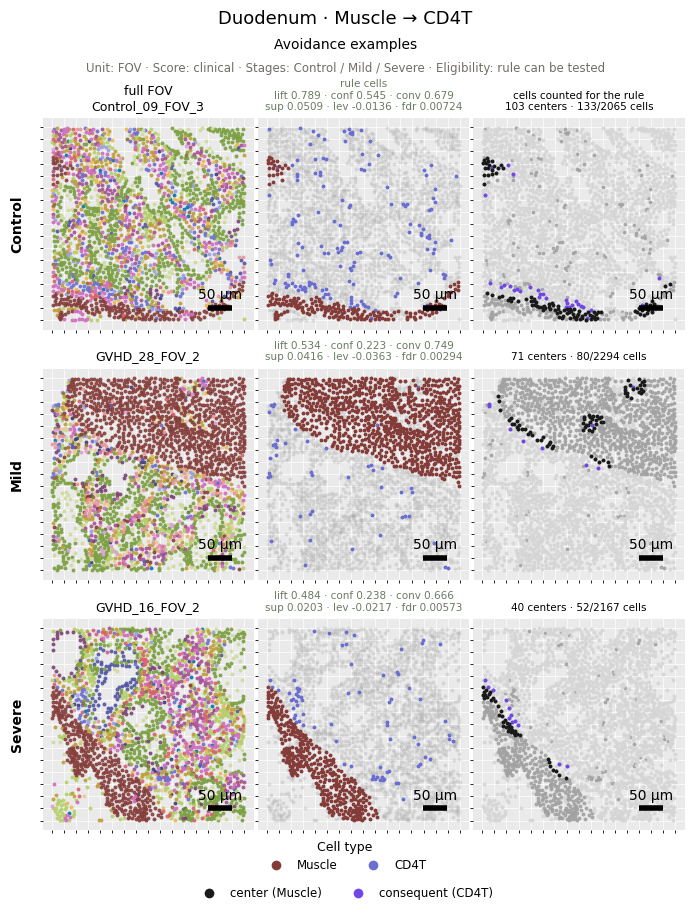

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_5a23eed2d4_parent_fovs_no_rule.pdf


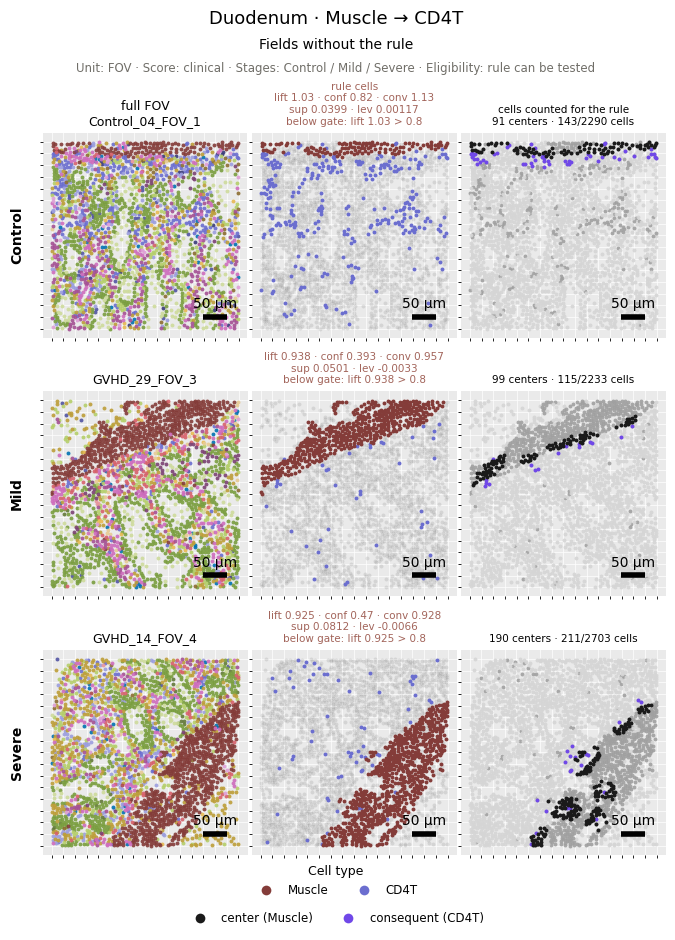

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_5a23eed2d4_complex_fovs_attraction.pdf


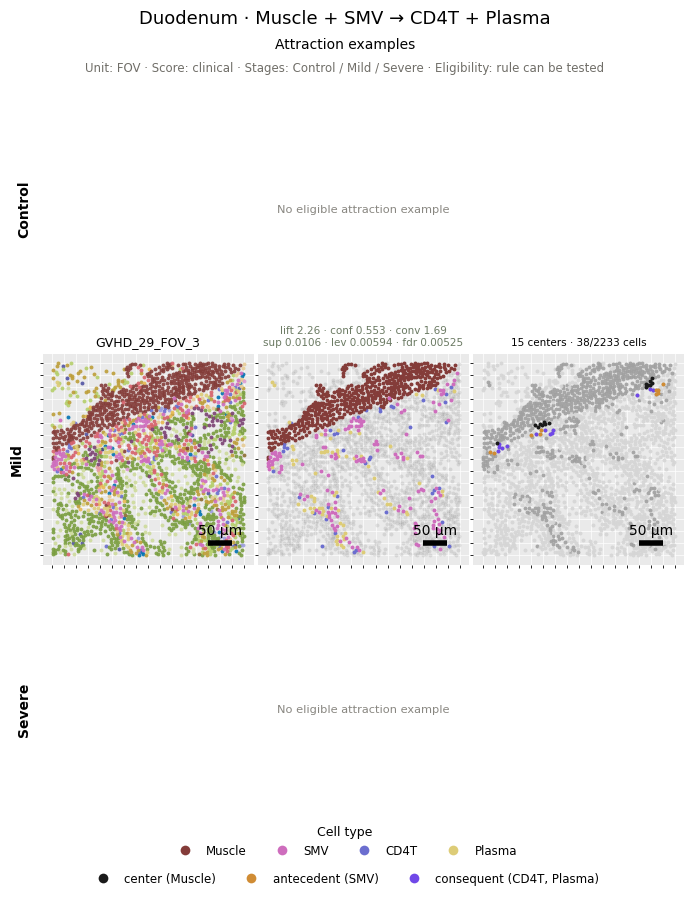

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_5a23eed2d4_complex_fovs_avoidance.pdf


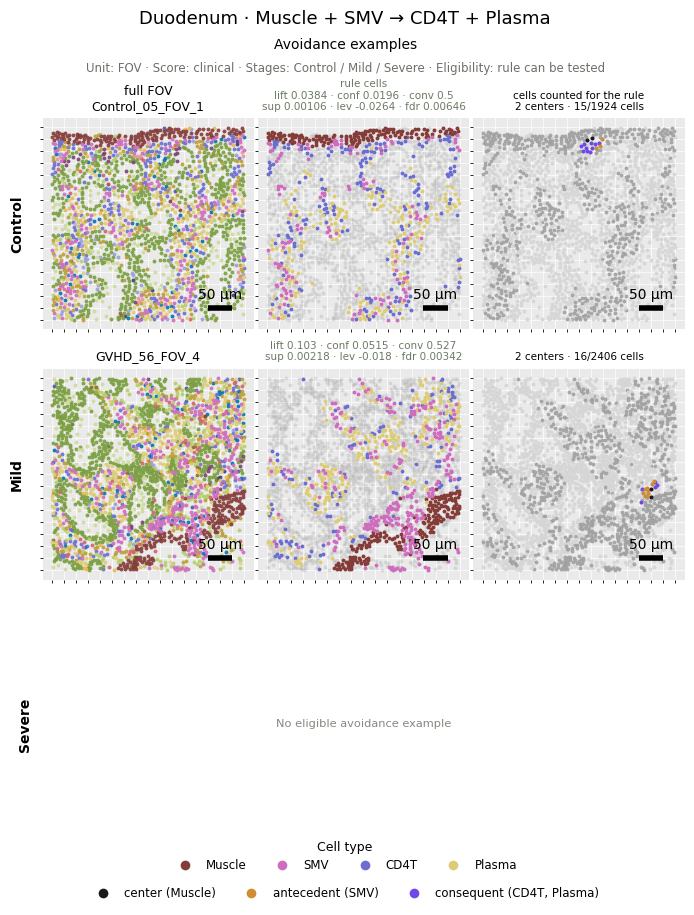

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_5a23eed2d4_complex_fovs_no_rule.pdf


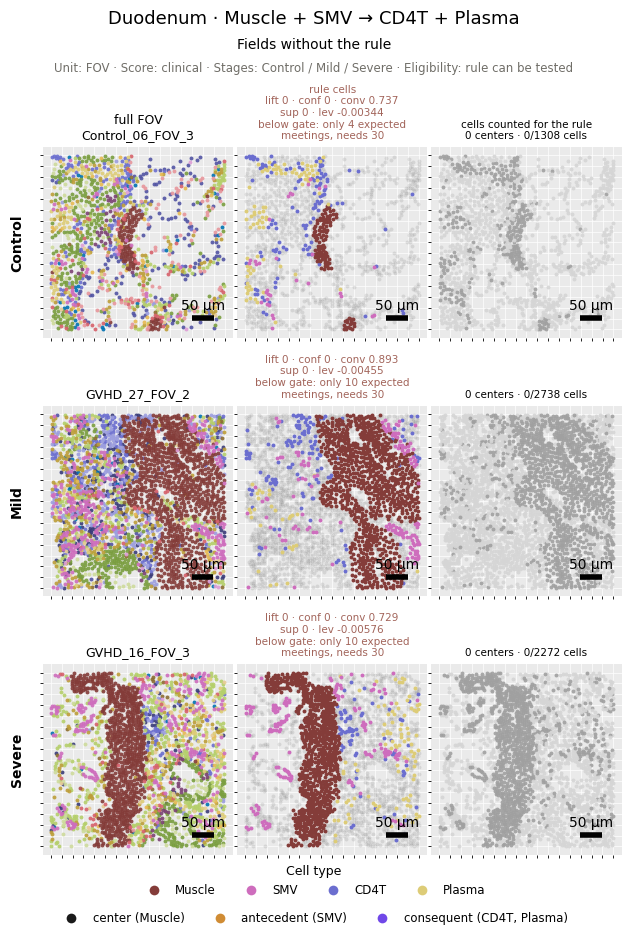

In [7]:
show_selected(1)

[2] Colon: Goblet + Macrophage -> Plasma  vs  Goblet + Macrophage -> CD4T + Plasma
FOVs testable for both rules; net = attraction share − avoidance share.


,stage,role,attraction,avoidance,eligible,patients,rule_patients,net
0,Control,parent,16,6,25,4,4,0.400000
1,Control,complex,6,15,25,4,4,-0.360000
2,Mild,parent,0,1,8,3,1,-0.125000
3,Mild,complex,0,1,8,3,1,-0.125000
4,Severe,parent,2,3,23,8,3,-0.043478
5,Severe,complex,1,1,23,8,2,0.000000


saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_ece65dc605_summary.pdf


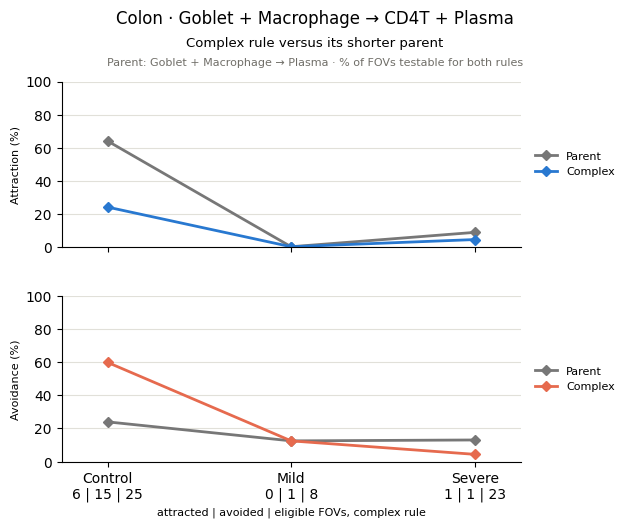

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_ece65dc605_parent_fovs_attraction.pdf


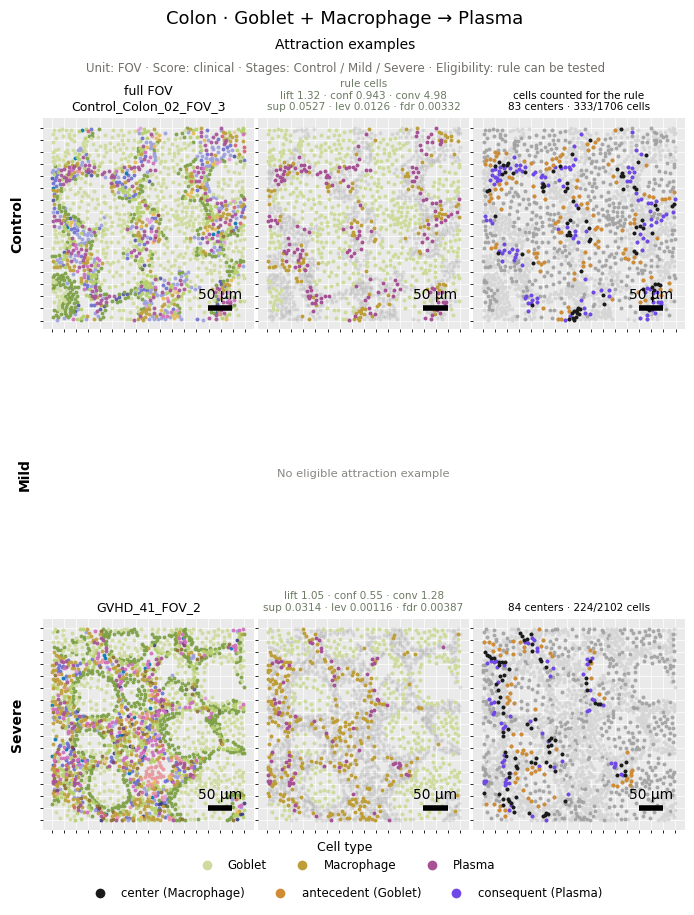

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_ece65dc605_parent_fovs_avoidance.pdf


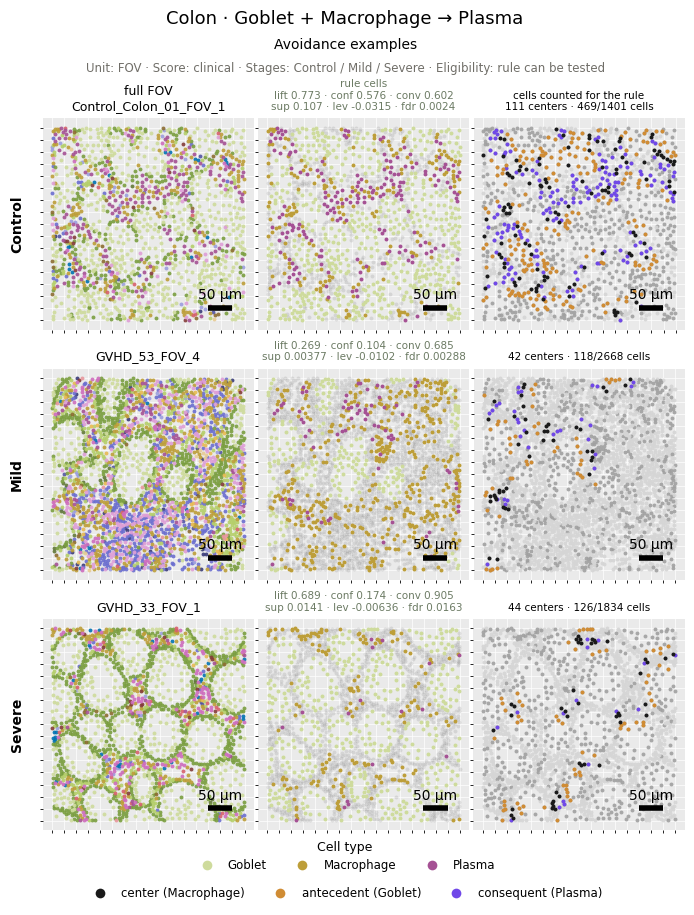

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_ece65dc605_parent_fovs_no_rule.pdf


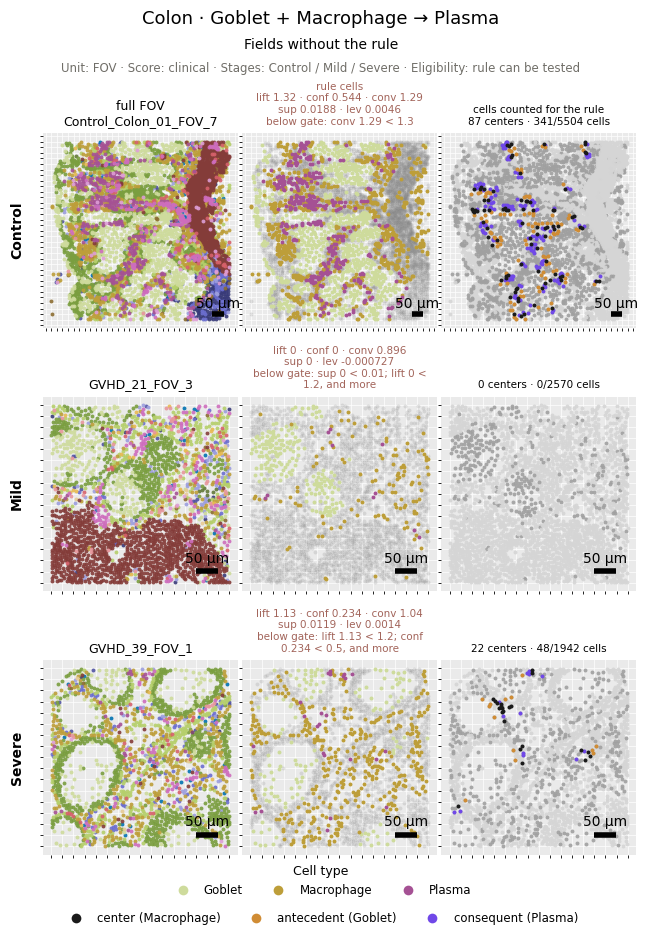

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_ece65dc605_complex_fovs_attraction.pdf


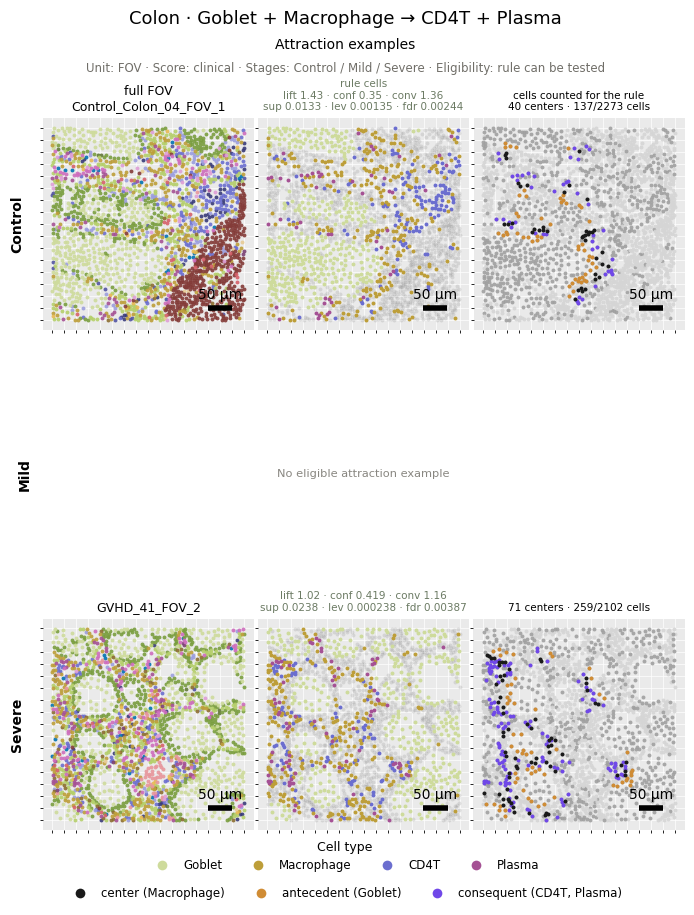

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_ece65dc605_complex_fovs_avoidance.pdf


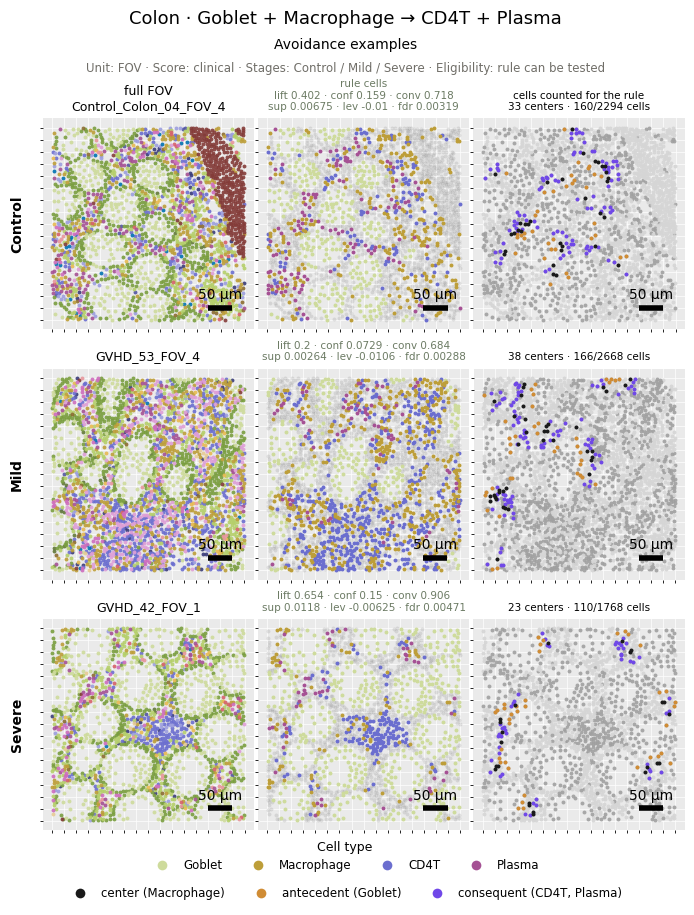

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_ece65dc605_complex_fovs_no_rule.pdf


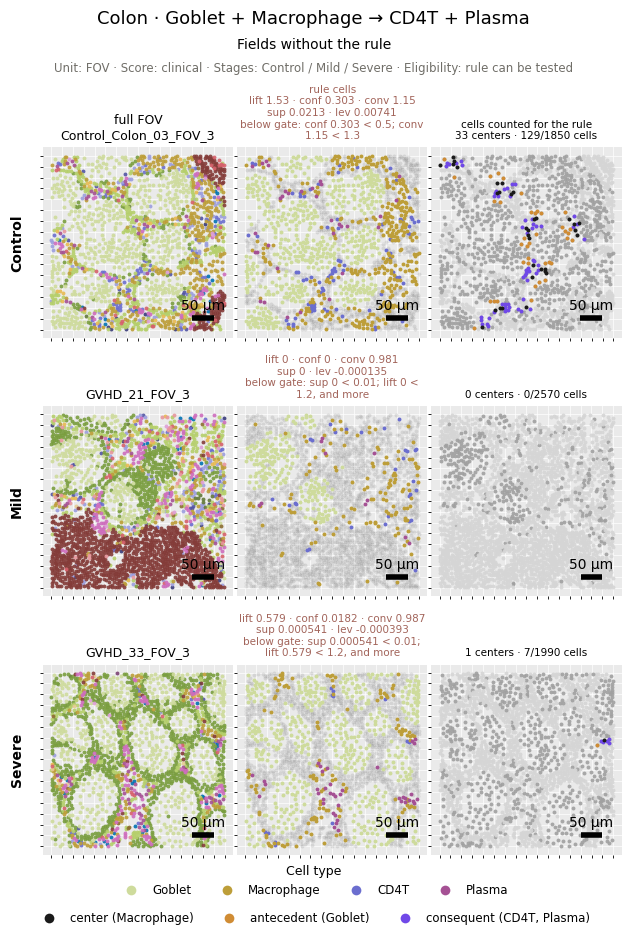

In [8]:
show_selected(2)

[3] Colon: CD8T -> Plasma  vs  CD8T + Goblet -> Fibroblast + Plasma
FOVs testable for both rules; net = attraction share − avoidance share.


,stage,role,attraction,avoidance,eligible,patients,rule_patients,net
0,Control,parent,10,0,25,4,4,0.40
1,Control,complex,4,13,25,4,4,-0.36
2,Mild,parent,0,0,8,2,0,0.00
3,Mild,complex,0,0,8,2,0,0.00
4,Severe,parent,0,0,21,9,0,0.00
5,Severe,complex,0,0,21,9,0,0.00


saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_2a1f73c9cf_summary.pdf


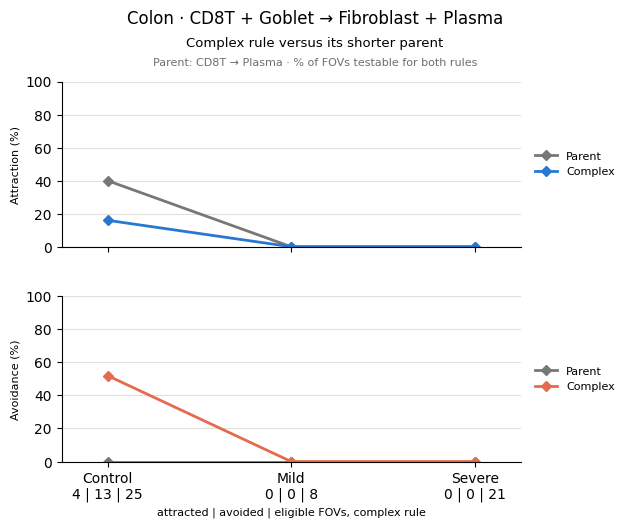

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_2a1f73c9cf_parent_fovs_attraction.pdf


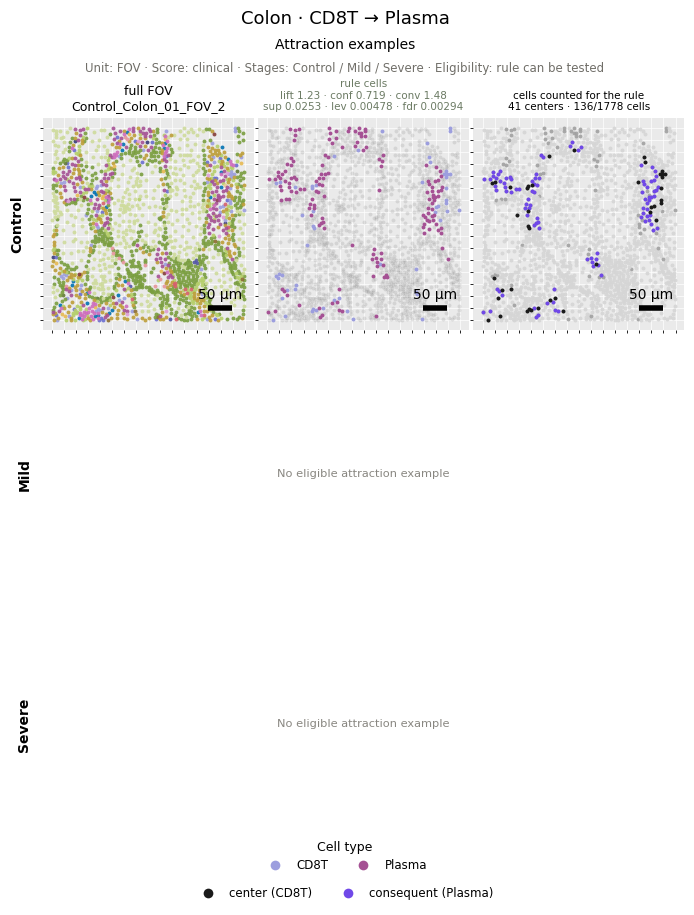

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_2a1f73c9cf_parent_fovs_no_rule.pdf


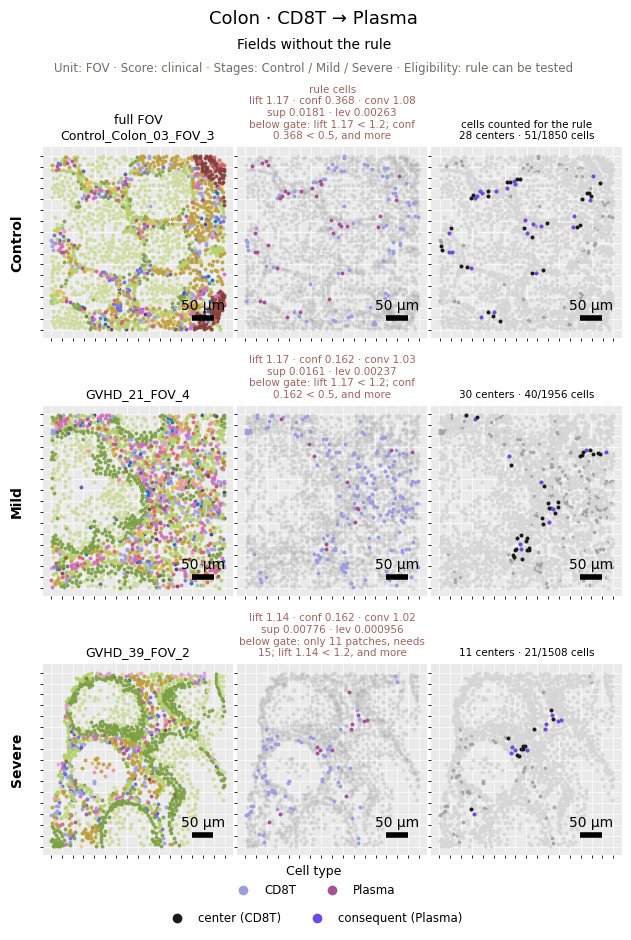

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_2a1f73c9cf_complex_fovs_attraction.pdf


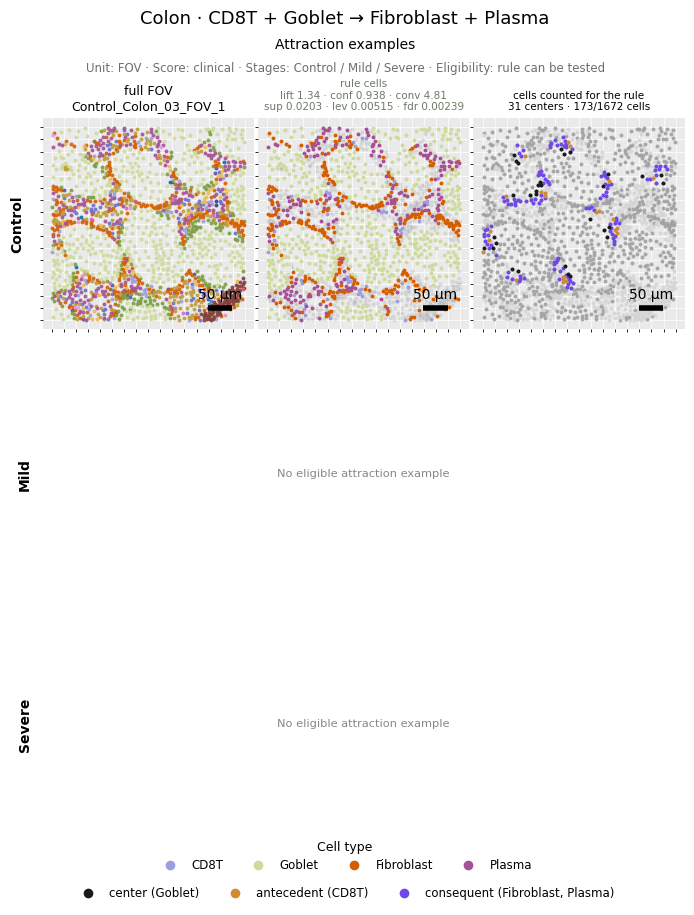

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_2a1f73c9cf_complex_fovs_avoidance.pdf


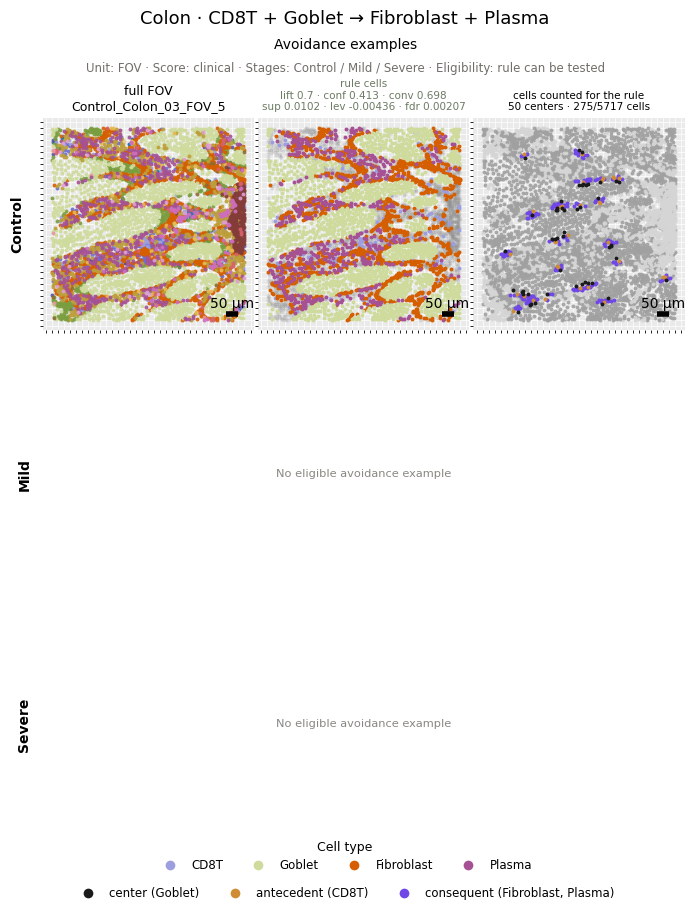

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_2a1f73c9cf_complex_fovs_no_rule.pdf


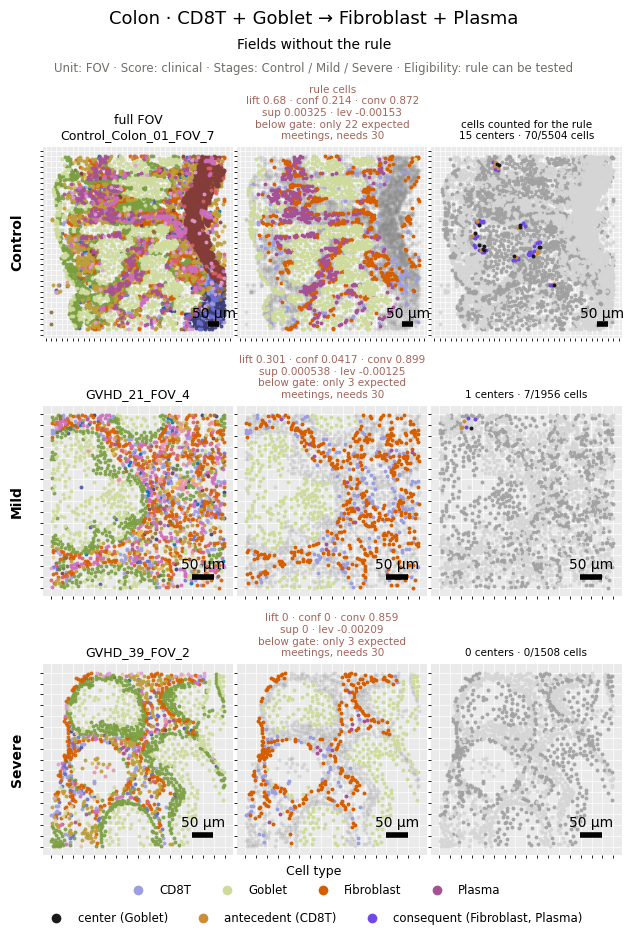

In [9]:
show_selected(3)

[4] Duodenum: Plasma -> Muscle  vs  Fibroblast + Plasma -> Muscle
FOVs testable for both rules; net = attraction share − avoidance share.


,stage,role,attraction,avoidance,eligible,patients,rule_patients,net
0,Control,parent,0,5,14,8,4,-0.357143
1,Control,complex,0,0,14,8,0,0.000000
2,Mild,parent,0,8,55,23,7,-0.145455
3,Mild,complex,0,11,55,23,9,-0.200000
4,Severe,parent,0,0,22,9,0,0.000000
5,Severe,complex,0,8,22,9,7,-0.363636


saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_9698e932da_summary.pdf


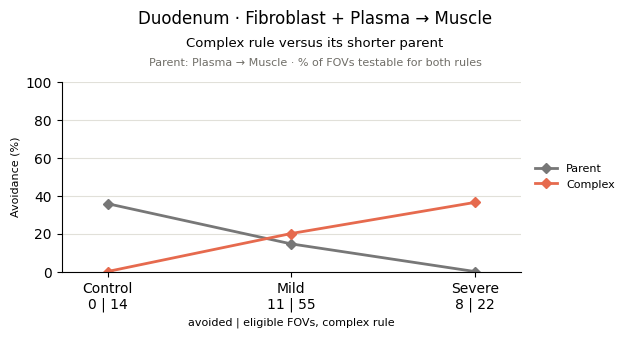

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_9698e932da_parent_fovs_avoidance.pdf


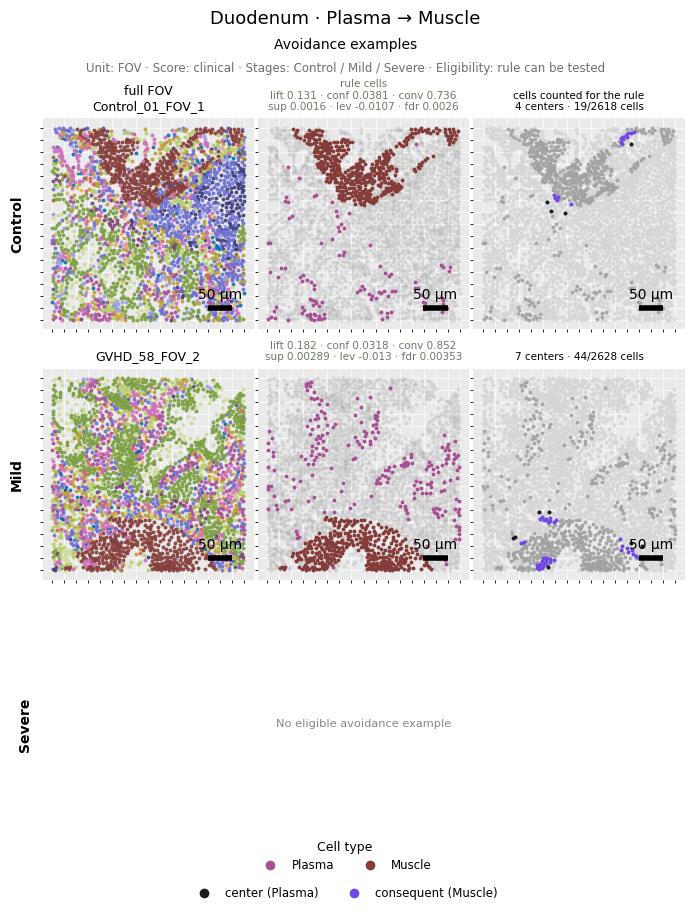

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_9698e932da_parent_fovs_no_rule.pdf


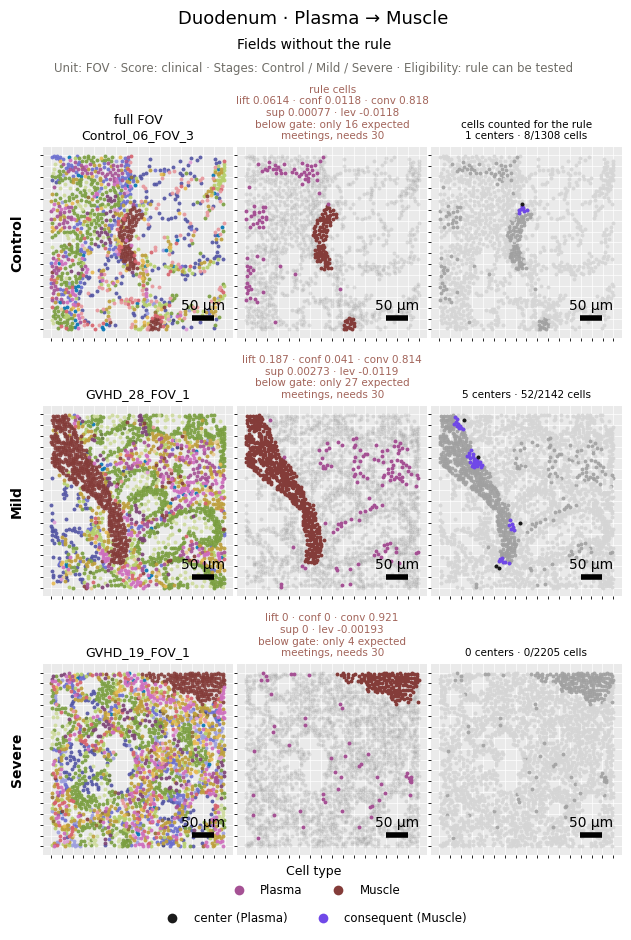

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_9698e932da_complex_fovs_avoidance.pdf


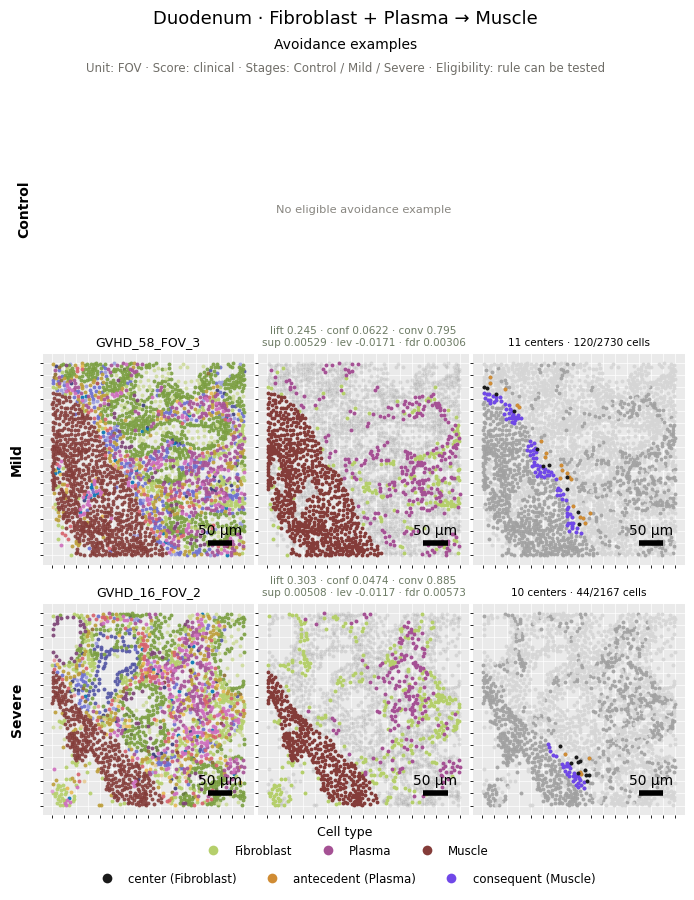

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_9698e932da_complex_fovs_no_rule.pdf


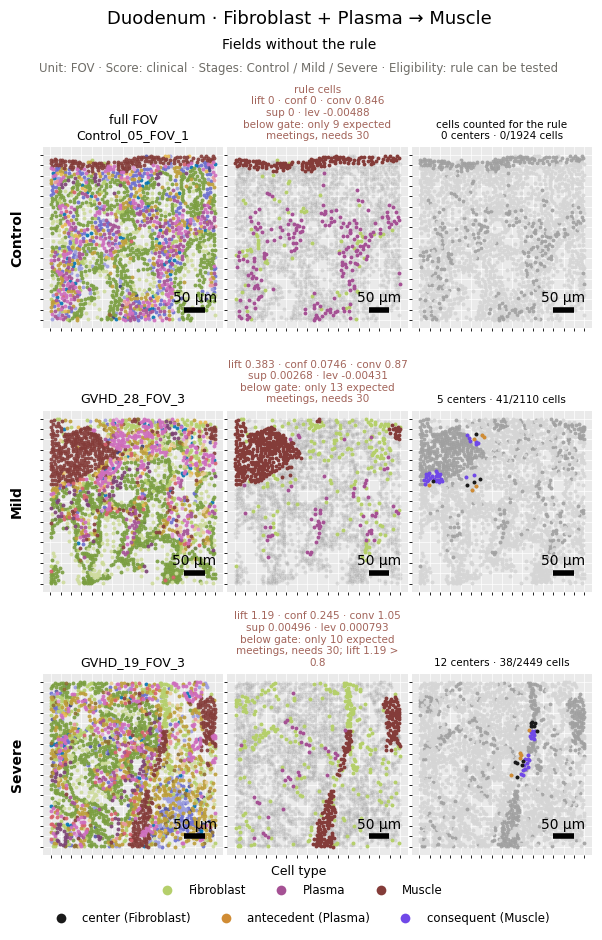

In [10]:
show_selected(4)

[5] Duodenum: Epithelial + Plasma -> Goblet  vs  Epithelial + Plasma -> Fibroblast + Goblet
FOVs testable for both rules; net = attraction share − avoidance share.


,stage,role,attraction,avoidance,eligible,patients,rule_patients,net
0,Control,parent,25,3,30,10,10,0.733333
1,Control,complex,3,5,30,10,6,-0.066667
2,Mild,parent,52,8,84,26,24,0.523810
3,Mild,complex,33,3,84,26,20,0.357143
4,Severe,parent,13,5,22,7,7,0.363636
5,Severe,complex,8,2,22,7,6,0.272727


saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_6d39294926_summary.pdf


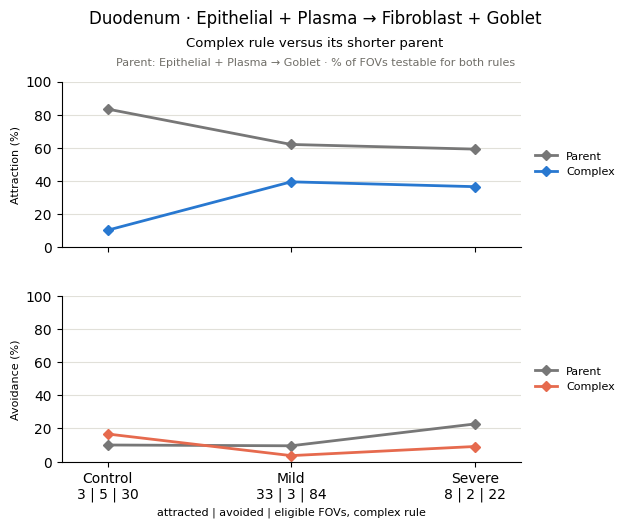

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_6d39294926_parent_fovs_attraction.pdf


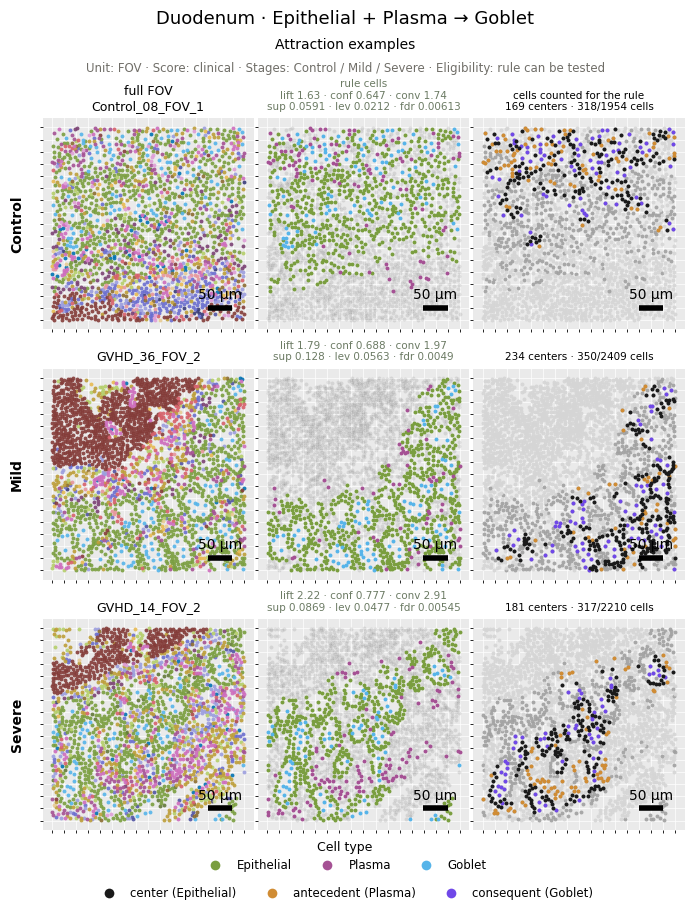

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_6d39294926_parent_fovs_avoidance.pdf


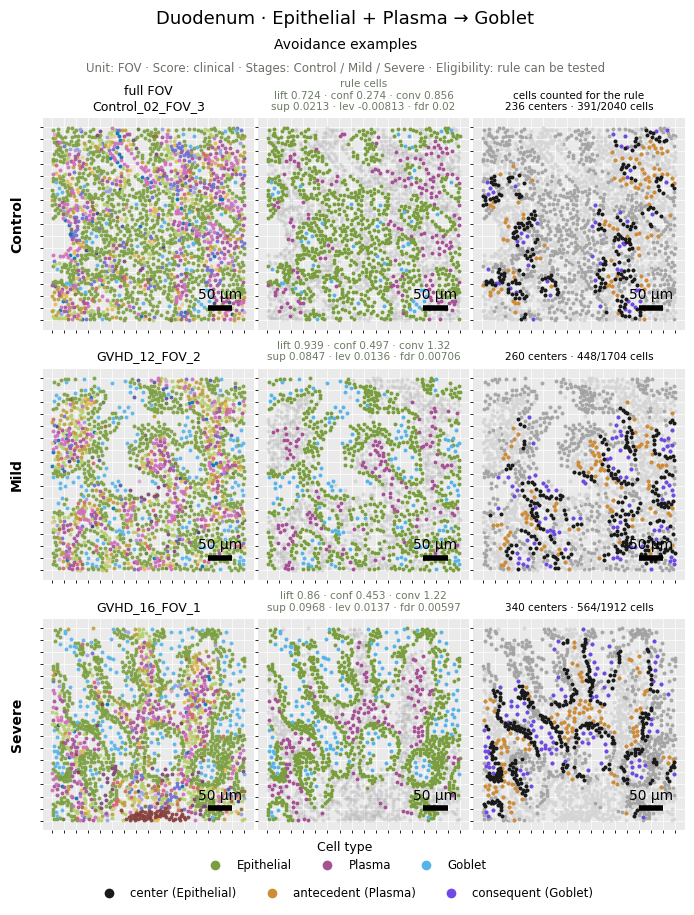

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_6d39294926_parent_fovs_no_rule.pdf


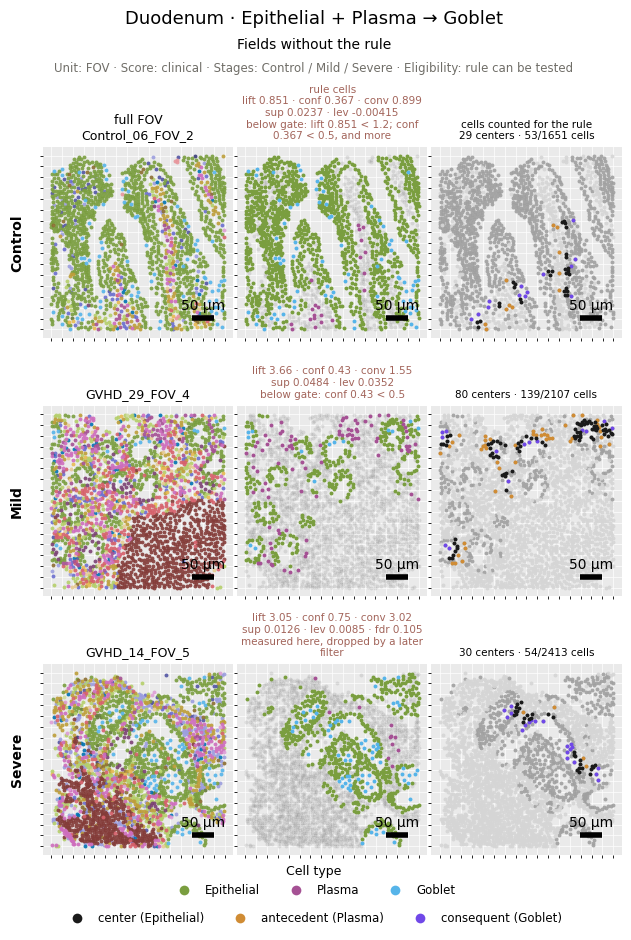

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_6d39294926_complex_fovs_attraction.pdf


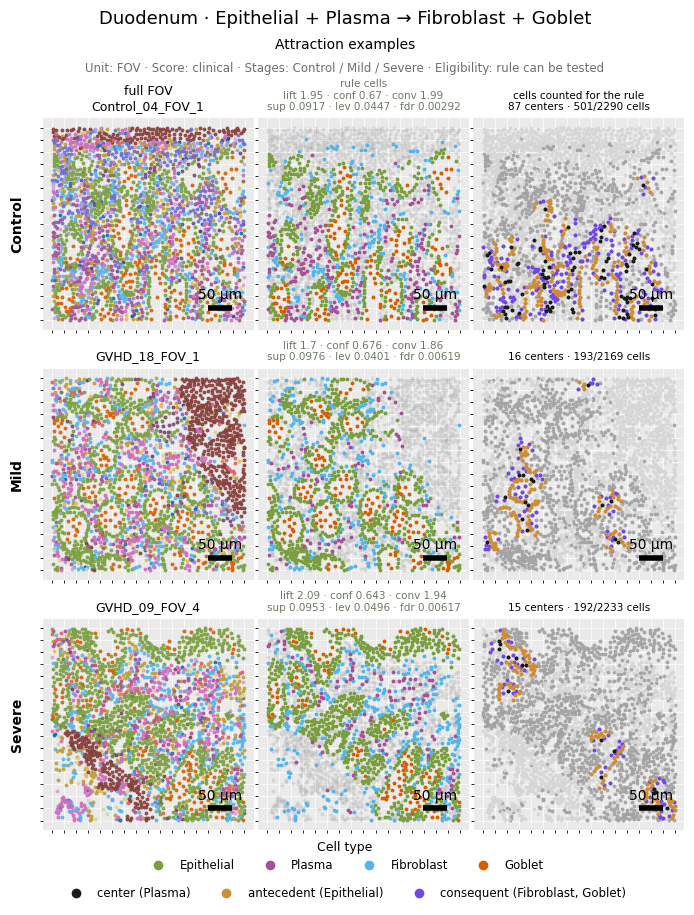

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_6d39294926_complex_fovs_avoidance.pdf


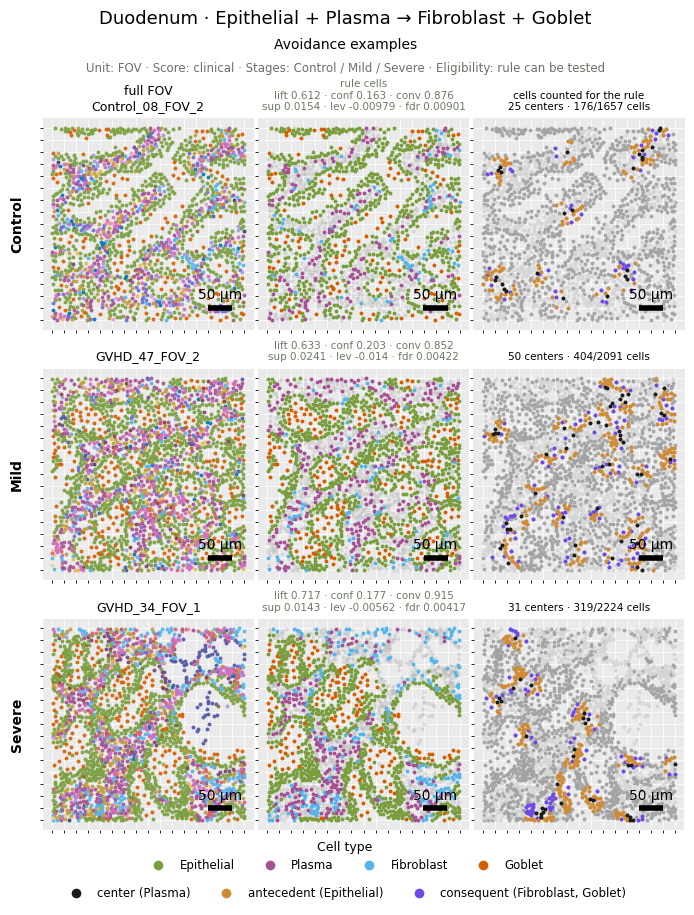

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_6d39294926_complex_fovs_no_rule.pdf


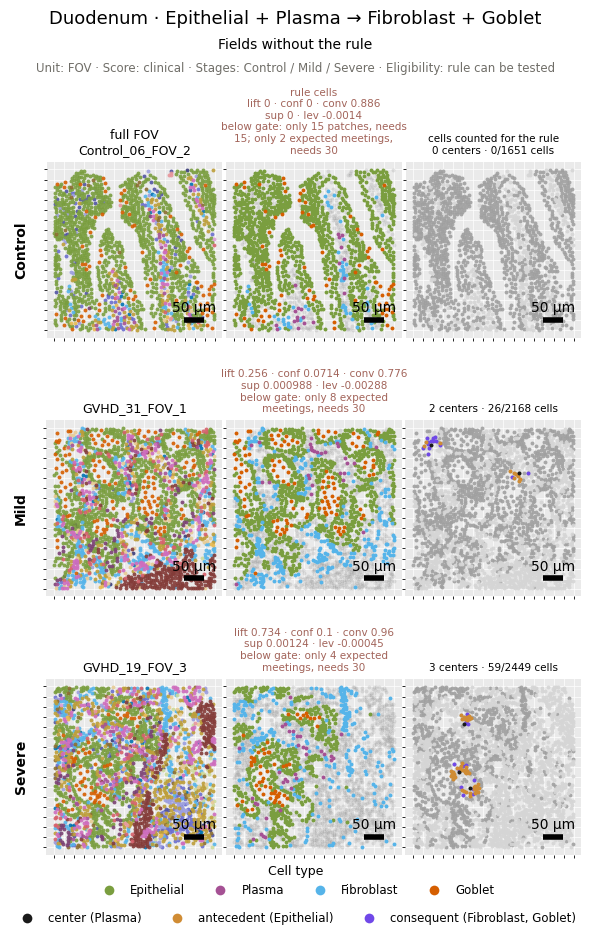

In [11]:
show_selected(5)

[6] Duodenum: Plasma -> Muscle  vs  Fibroblast + Macrophage + Plasma -> Muscle
FOVs testable for both rules; net = attraction share − avoidance share.


,stage,role,attraction,avoidance,eligible,patients,rule_patients,net
0,Control,parent,0,5,14,8,4,-0.357143
1,Control,complex,0,1,14,8,1,-0.071429
2,Mild,parent,0,8,55,23,7,-0.145455
3,Mild,complex,0,11,55,23,9,-0.200000
4,Severe,parent,0,0,22,9,0,0.000000
5,Severe,complex,0,9,22,9,7,-0.409091


saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_de8e5f0e3f_summary.pdf


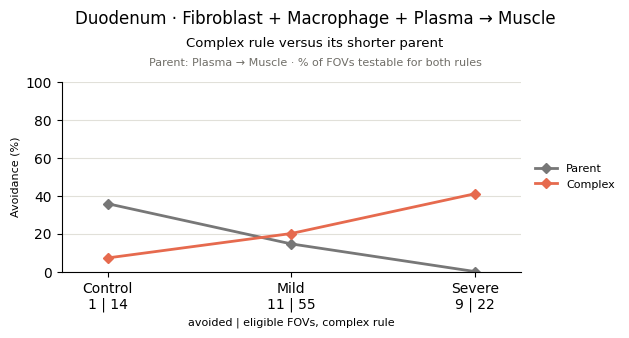

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_de8e5f0e3f_parent_fovs_avoidance.pdf


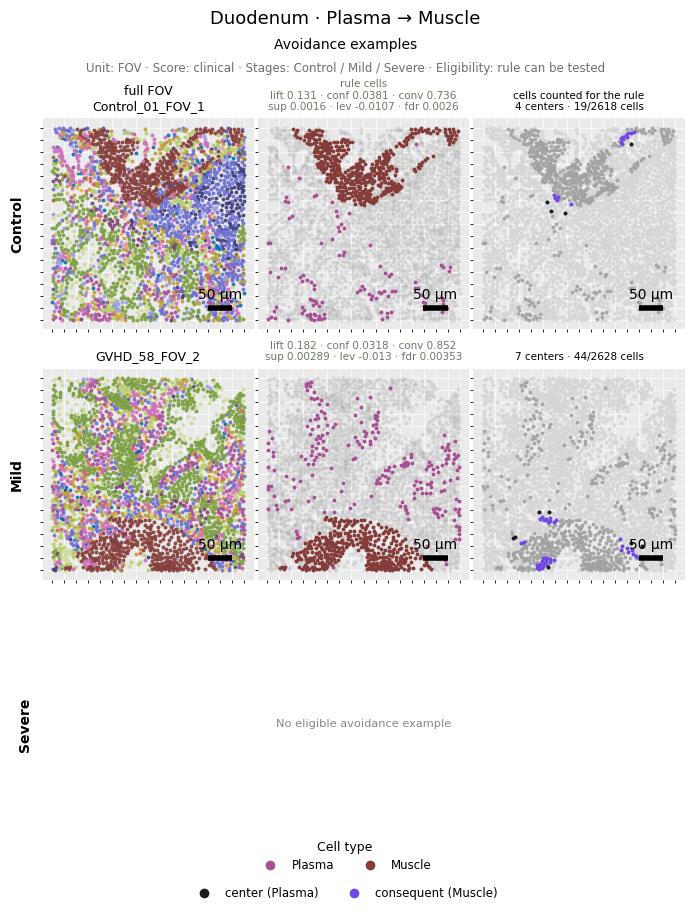

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_de8e5f0e3f_parent_fovs_no_rule.pdf


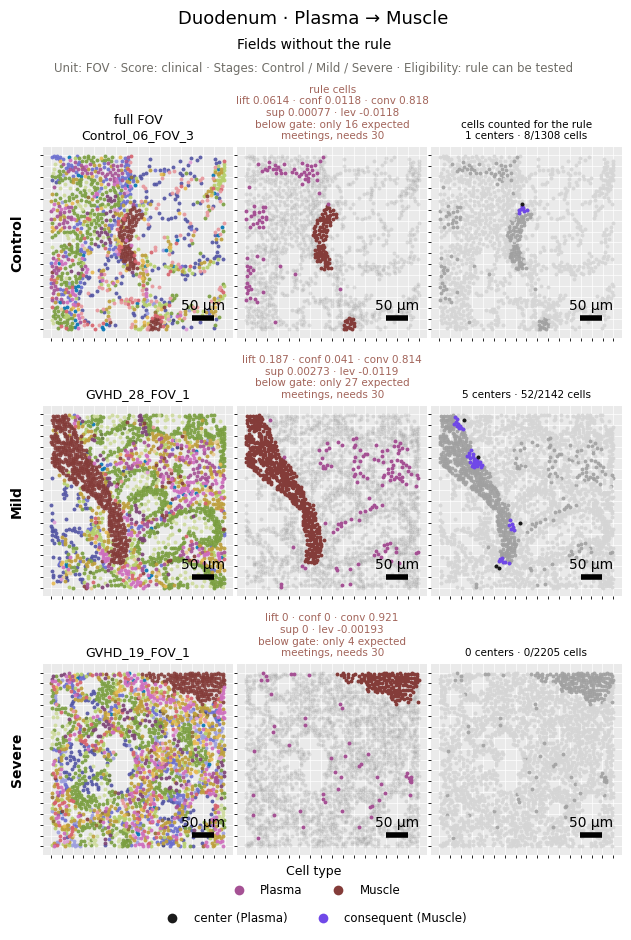

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_de8e5f0e3f_complex_fovs_avoidance.pdf


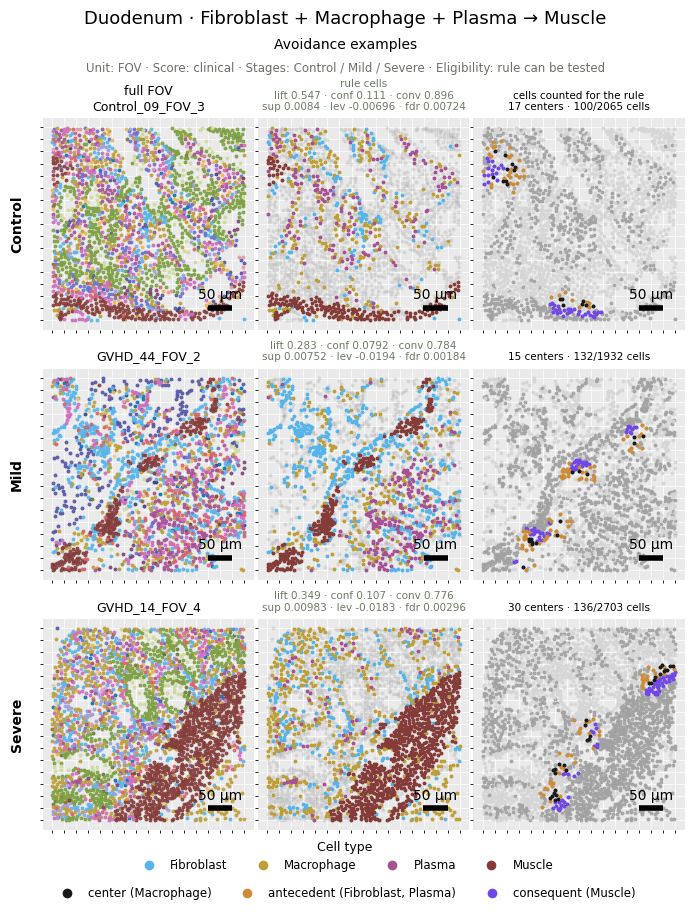

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_de8e5f0e3f_complex_fovs_no_rule.pdf


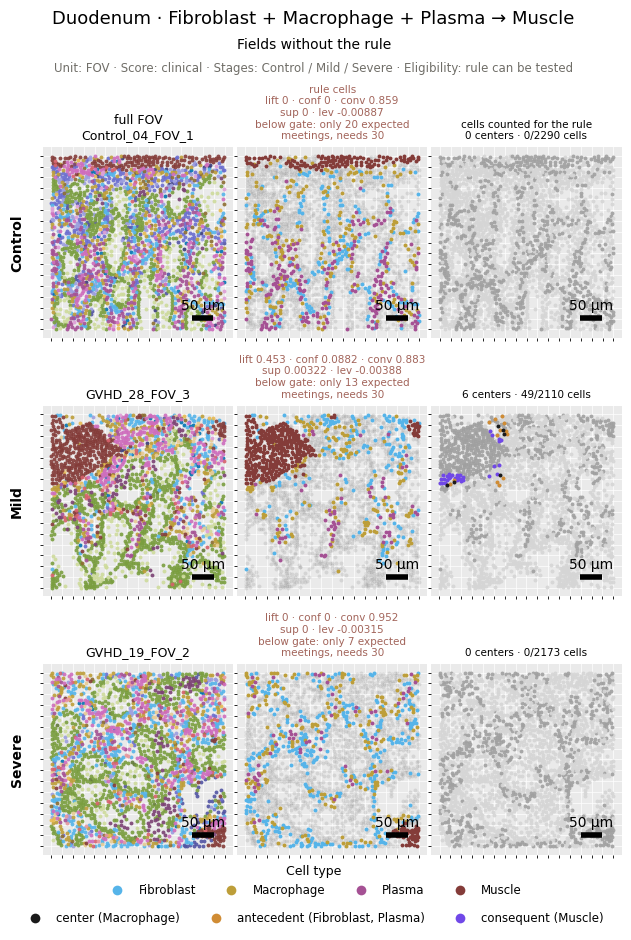

In [12]:
show_selected(6)

[7] Duodenum: Muscle -> CD4T  vs  Muscle + Neuron -> CD4T + Plasma
FOVs testable for both rules; net = attraction share − avoidance share.


,stage,role,attraction,avoidance,eligible,patients,rule_patients,net
0,Control,parent,1,3,13,7,3,-0.153846
1,Control,complex,0,5,13,7,4,-0.384615
2,Mild,parent,1,30,52,22,18,-0.557692
3,Mild,complex,0,13,52,22,8,-0.250000
4,Severe,parent,0,16,21,8,7,-0.761905
5,Severe,complex,0,1,21,8,1,-0.047619


saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_fc37518541_summary.pdf


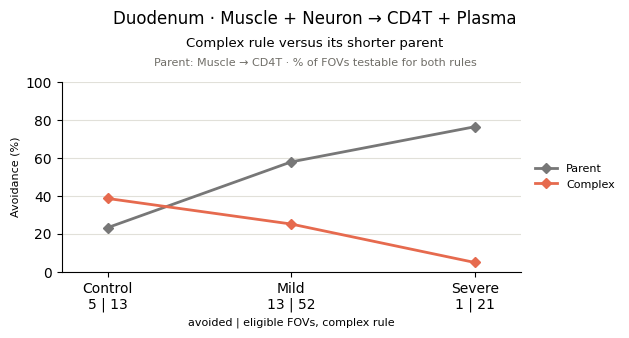

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_fc37518541_parent_fovs_attraction.pdf


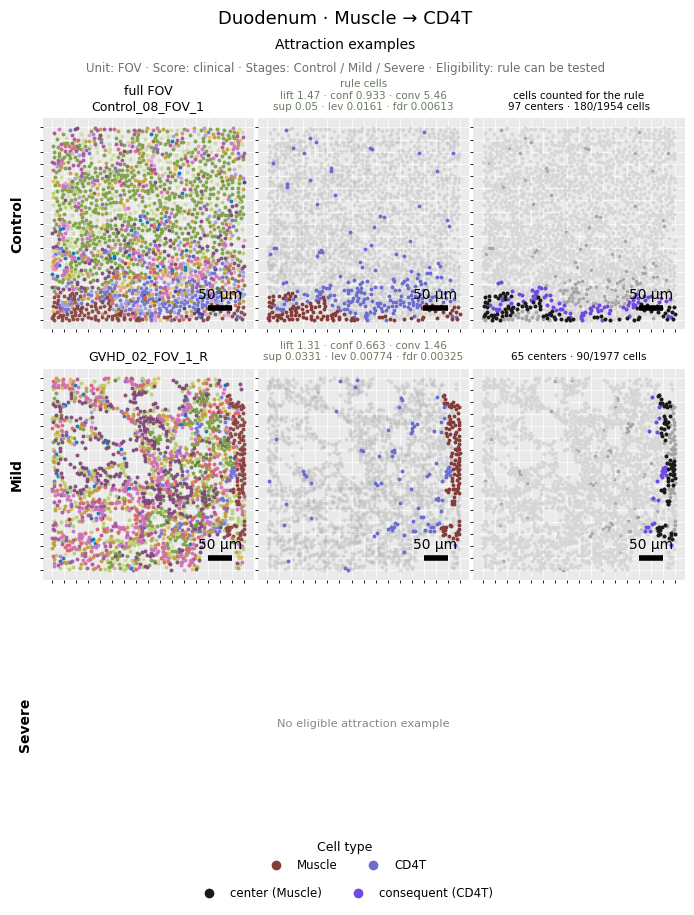

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_fc37518541_parent_fovs_avoidance.pdf


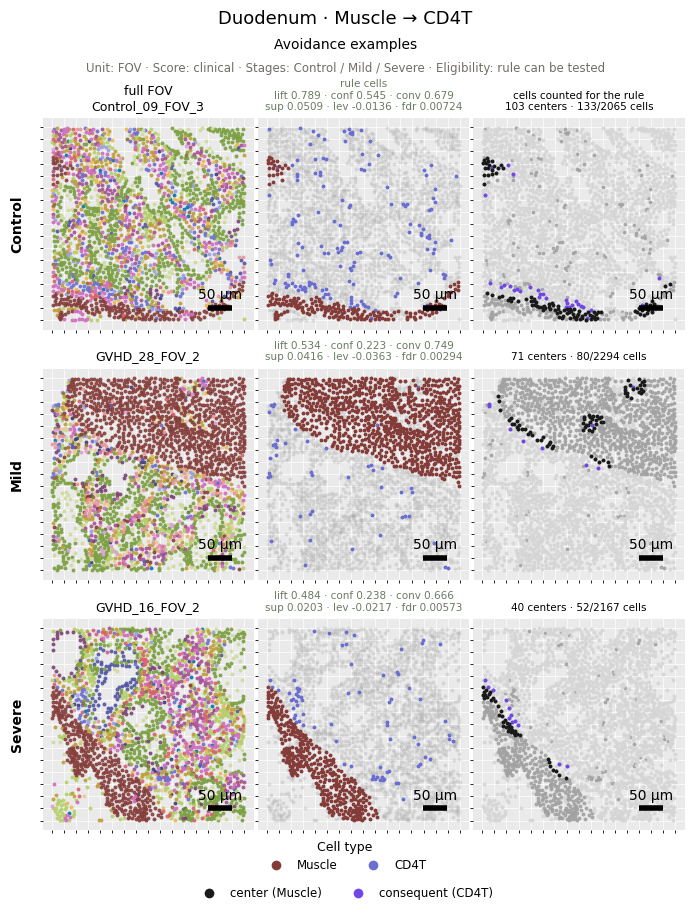

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_fc37518541_parent_fovs_no_rule.pdf


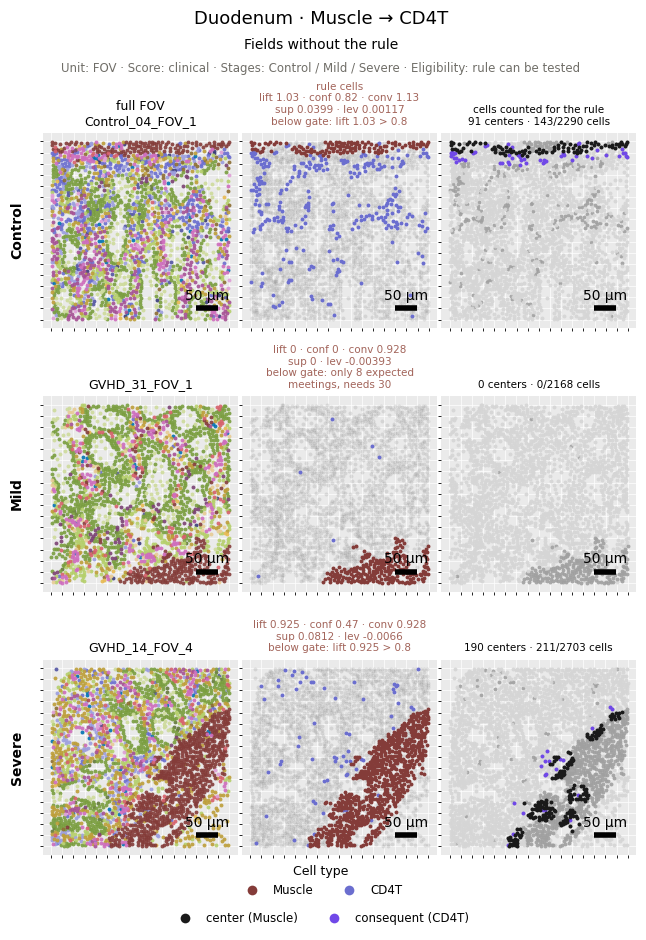

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_fc37518541_complex_fovs_avoidance.pdf


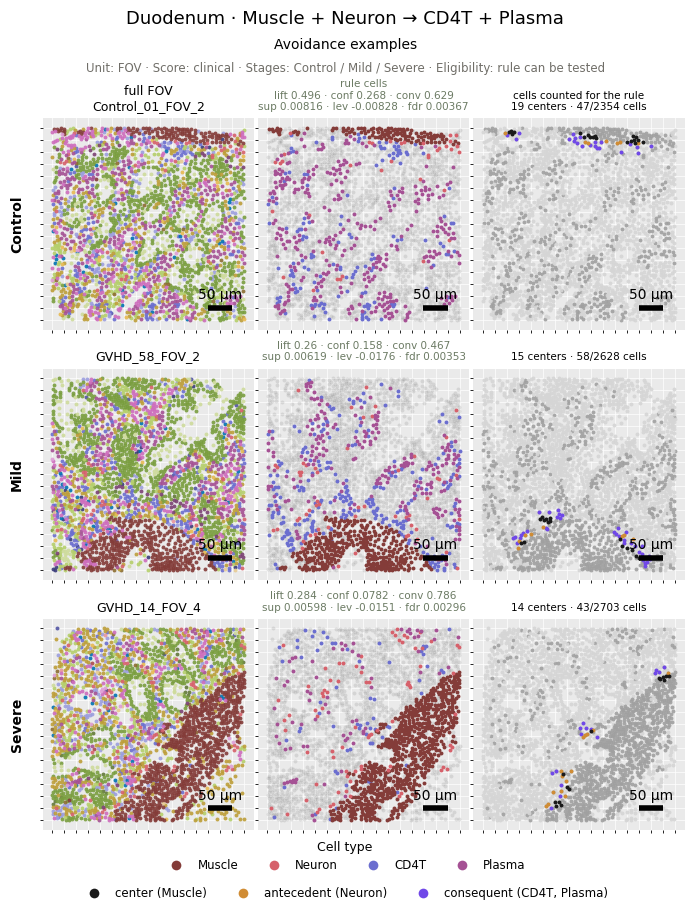

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_fc37518541_complex_fovs_no_rule.pdf


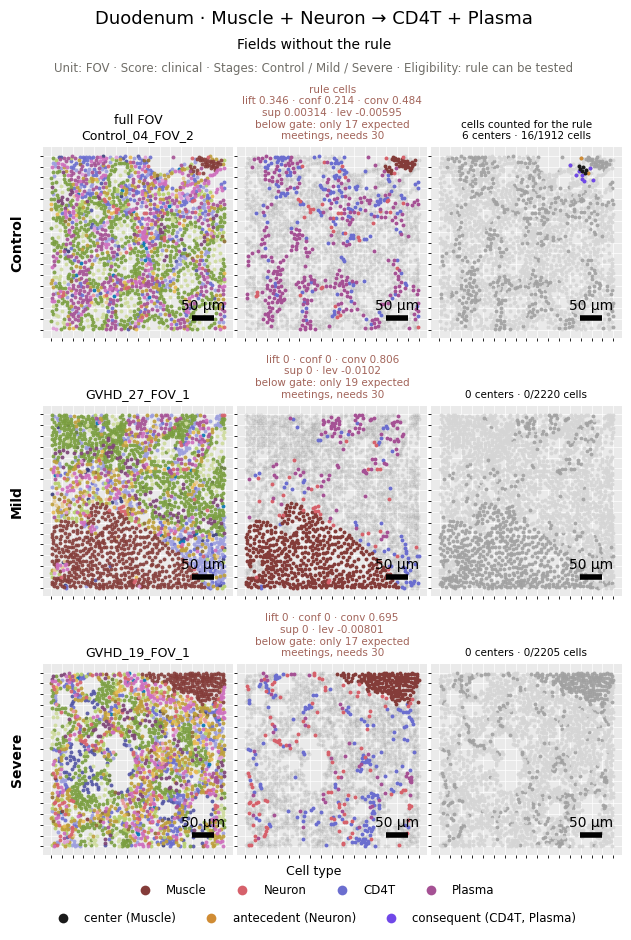

In [13]:
show_selected(7)

[8] Duodenum: Fibroblast -> Goblet  vs  CD4T + Fibroblast + Plasma -> Goblet
FOVs testable for both rules; net = attraction share − avoidance share.


,stage,role,attraction,avoidance,eligible,patients,rule_patients,net
0,Control,parent,0,17,30,10,8,-0.566667
1,Control,complex,0,20,30,10,9,-0.666667
2,Mild,parent,0,58,75,24,23,-0.773333
3,Mild,complex,0,31,75,24,14,-0.413333
4,Severe,parent,0,18,20,7,7,-0.900000
5,Severe,complex,0,6,20,7,5,-0.300000


saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_545b98efd7_summary.pdf


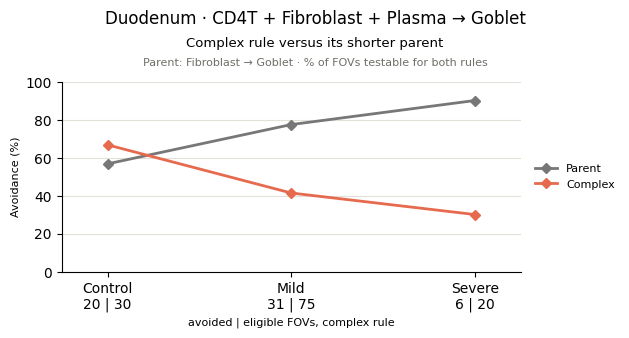

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_545b98efd7_parent_fovs_avoidance.pdf


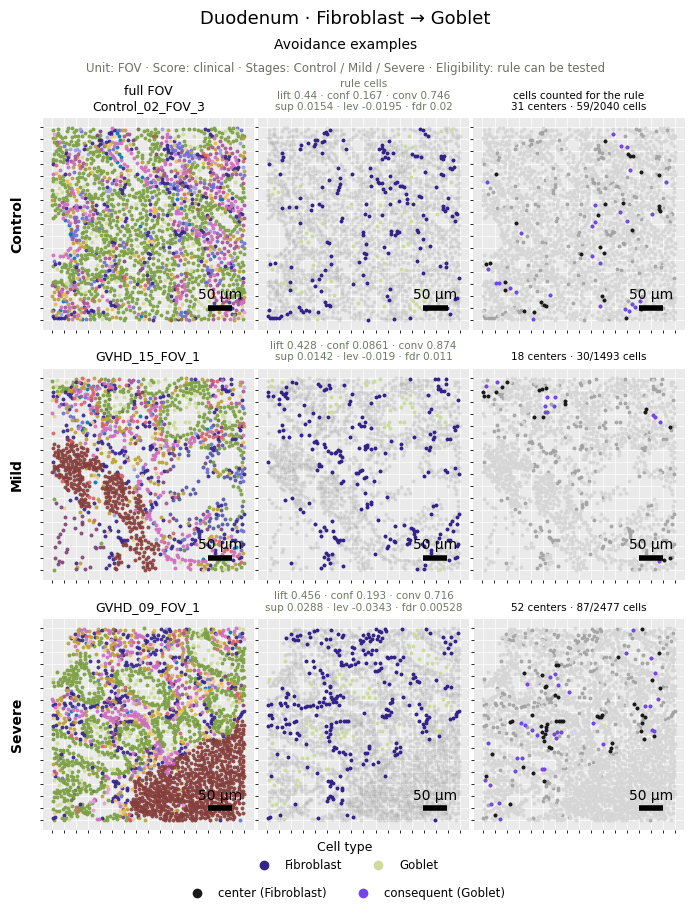

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_545b98efd7_parent_fovs_no_rule.pdf


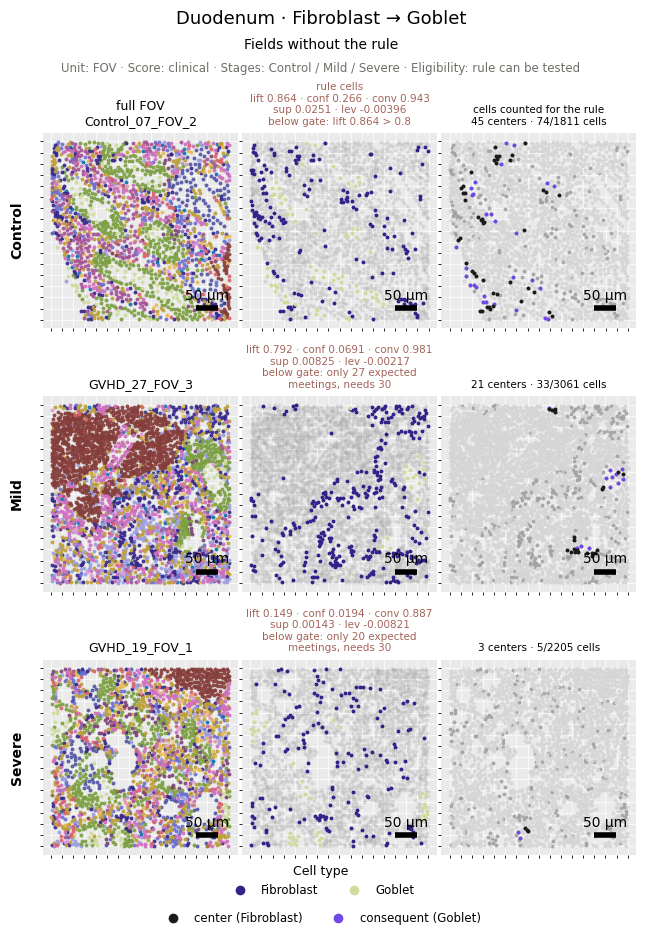

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_545b98efd7_complex_fovs_avoidance.pdf


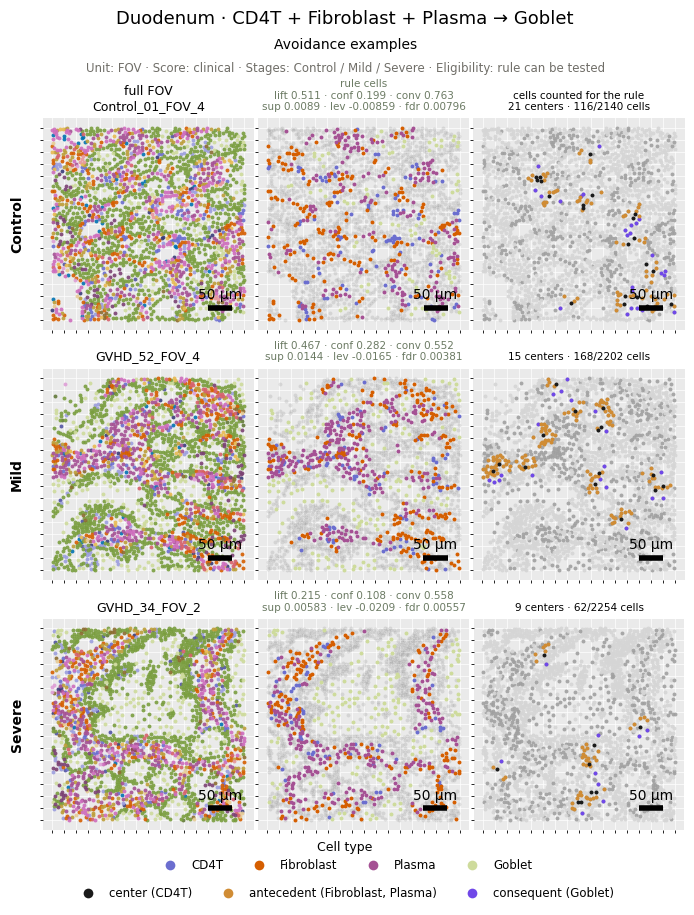

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_545b98efd7_complex_fovs_no_rule.pdf


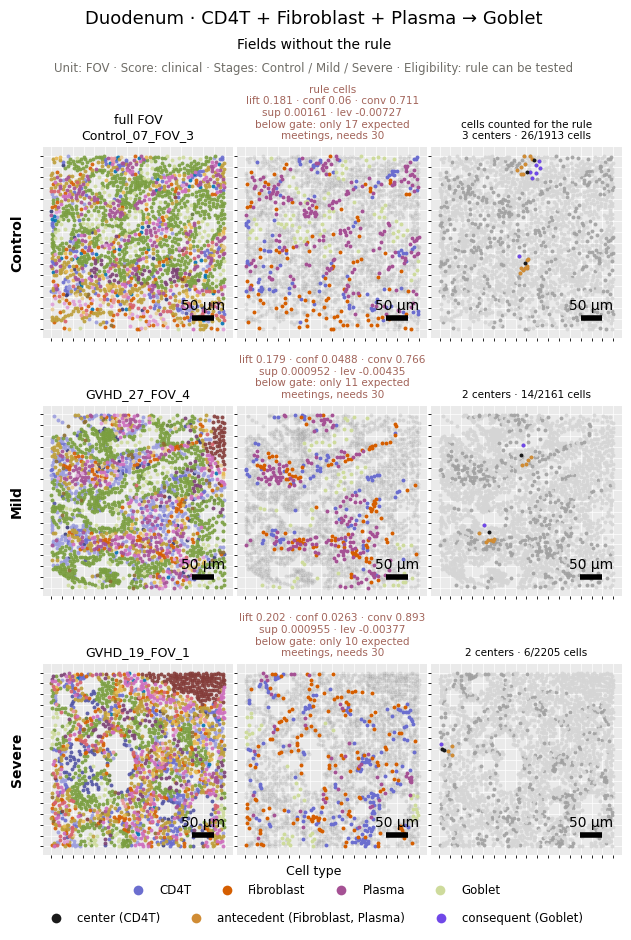

In [14]:
show_selected(8)

[9] Colon: CD4T -> Goblet  vs  CD4T + Epithelial + Macrophage -> Goblet
FOVs testable for both rules; net = attraction share − avoidance share.


,stage,role,attraction,avoidance,eligible,patients,rule_patients,net
0,Control,parent,0,15,25,4,4,-0.600000
1,Control,complex,19,2,25,4,4,0.680000
2,Mild,parent,0,4,9,3,1,-0.444444
3,Mild,complex,6,1,9,3,3,0.555556
4,Severe,parent,1,12,40,12,6,-0.275000
5,Severe,complex,17,15,40,12,11,0.050000


saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_4b9a04ddbe_summary.pdf


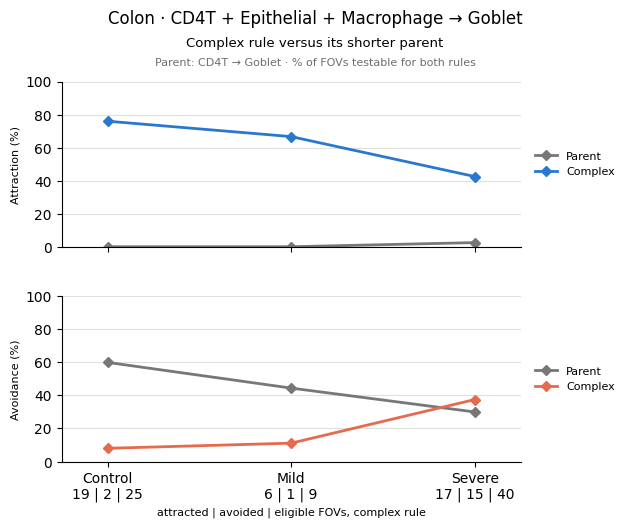

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_4b9a04ddbe_parent_fovs_attraction.pdf


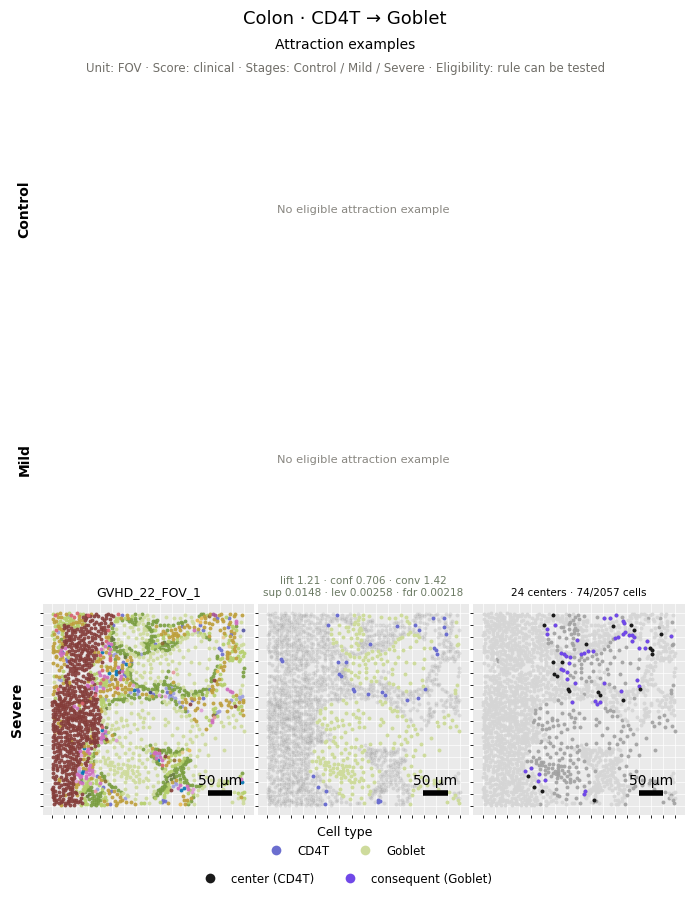

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_4b9a04ddbe_parent_fovs_avoidance.pdf


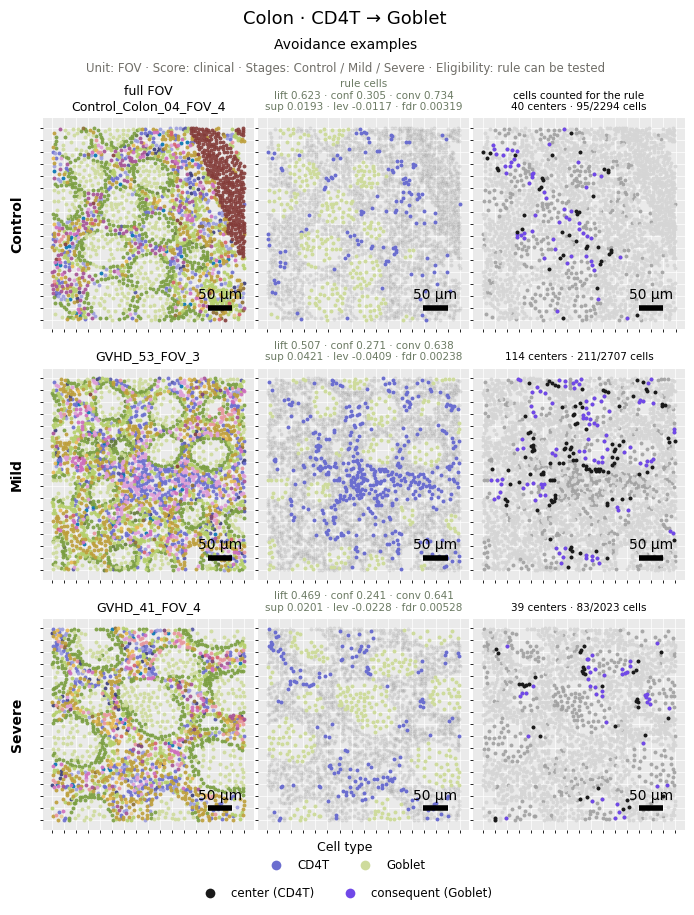

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_4b9a04ddbe_parent_fovs_no_rule.pdf


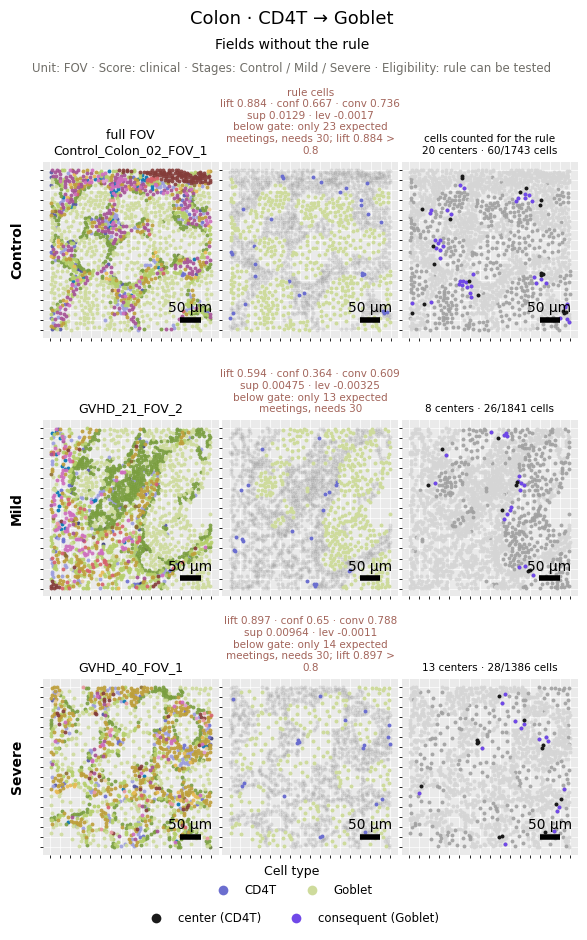

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_4b9a04ddbe_complex_fovs_attraction.pdf


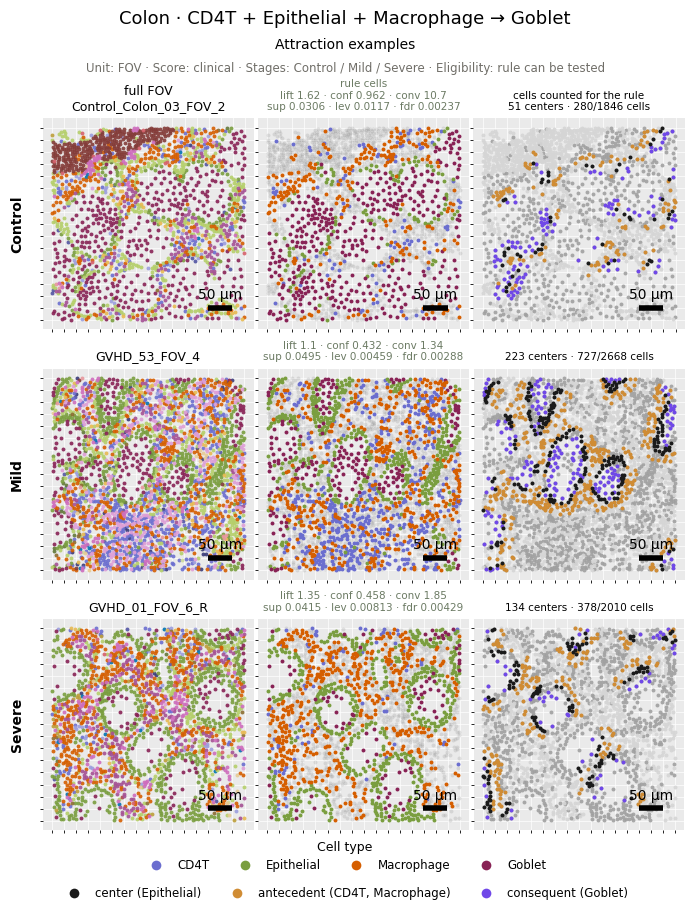

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_4b9a04ddbe_complex_fovs_avoidance.pdf


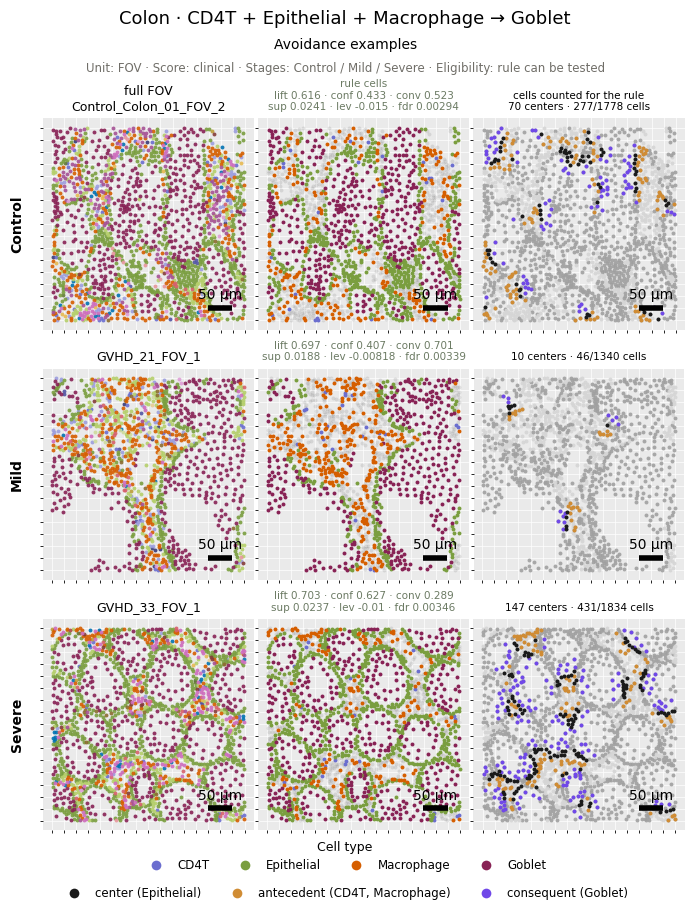

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_4b9a04ddbe_complex_fovs_no_rule.pdf


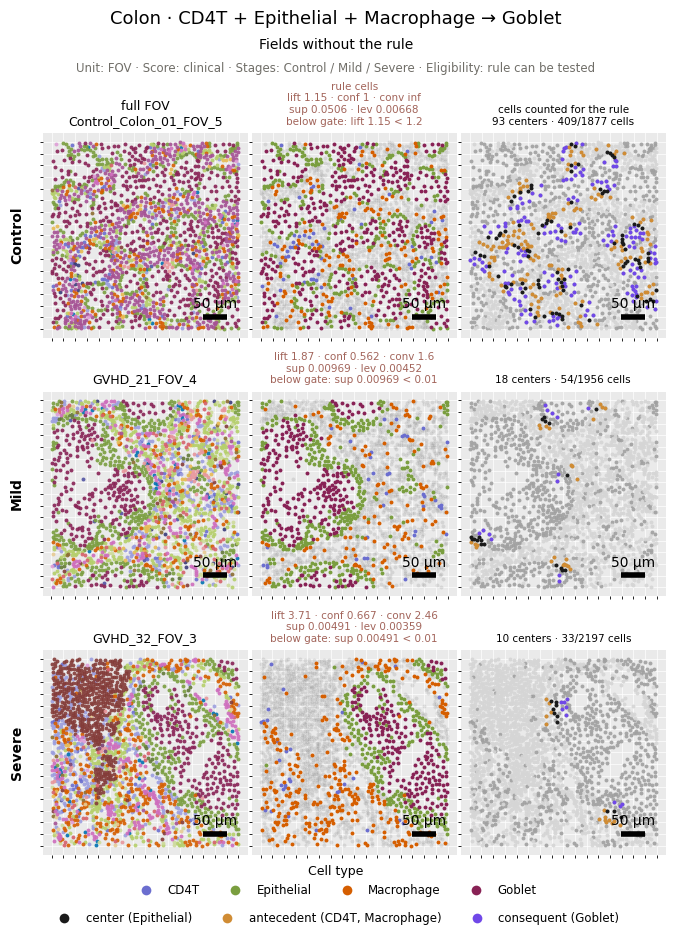

In [15]:
show_selected(9)

[10] Duodenum: CD8T + Muscle -> Fibroblast  vs  CD8T + Muscle -> Endothelial + Fibroblast
FOVs testable for both rules; net = attraction share − avoidance share.


,stage,role,attraction,avoidance,eligible,patients,rule_patients,net
0,Control,parent,0,6,12,8,5,-0.500000
1,Control,complex,0,0,12,8,0,0.000000
2,Mild,parent,3,8,26,12,7,-0.192308
3,Mild,complex,0,2,26,12,1,-0.076923
4,Severe,parent,2,5,17,6,3,-0.176471
5,Severe,complex,0,8,17,6,4,-0.470588


saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_6eadd755c3_summary.pdf


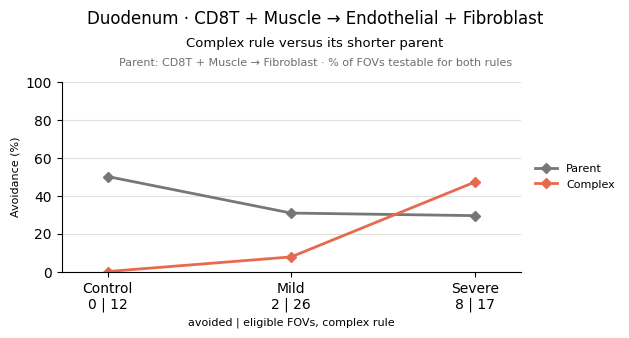

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_6eadd755c3_parent_fovs_attraction.pdf


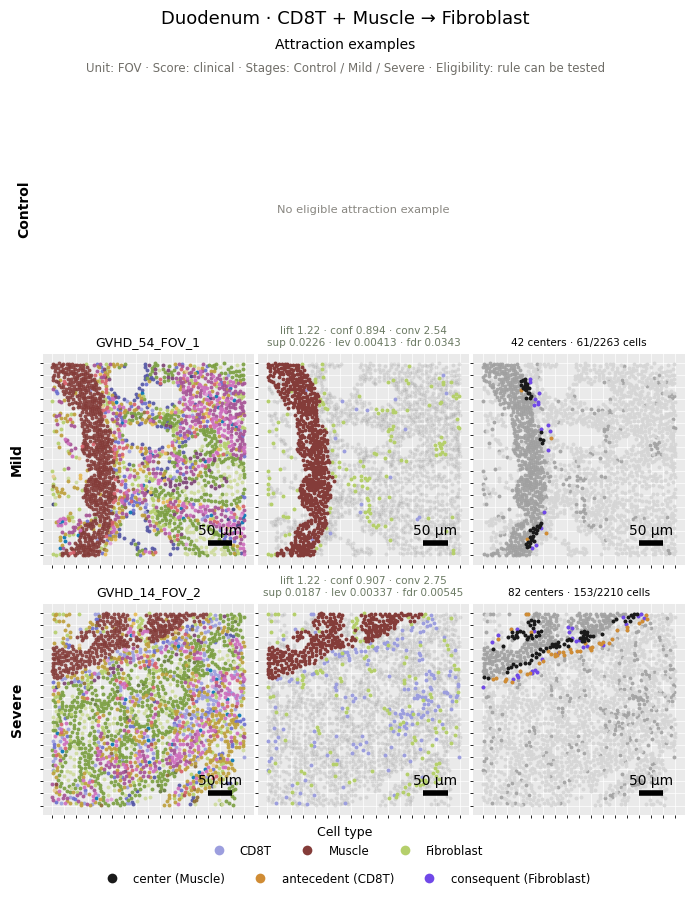

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_6eadd755c3_parent_fovs_avoidance.pdf


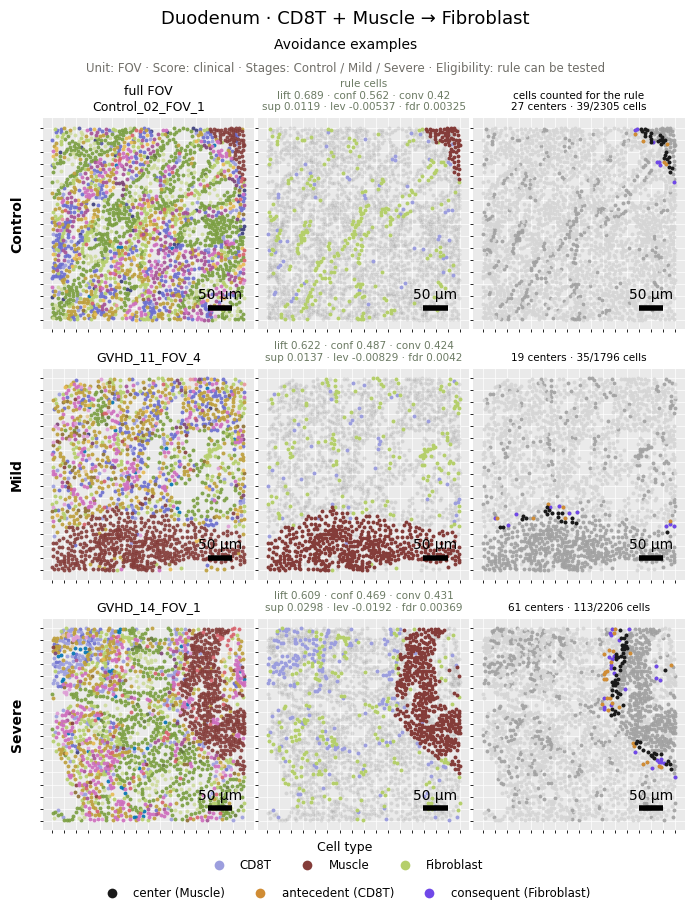

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_6eadd755c3_parent_fovs_no_rule.pdf


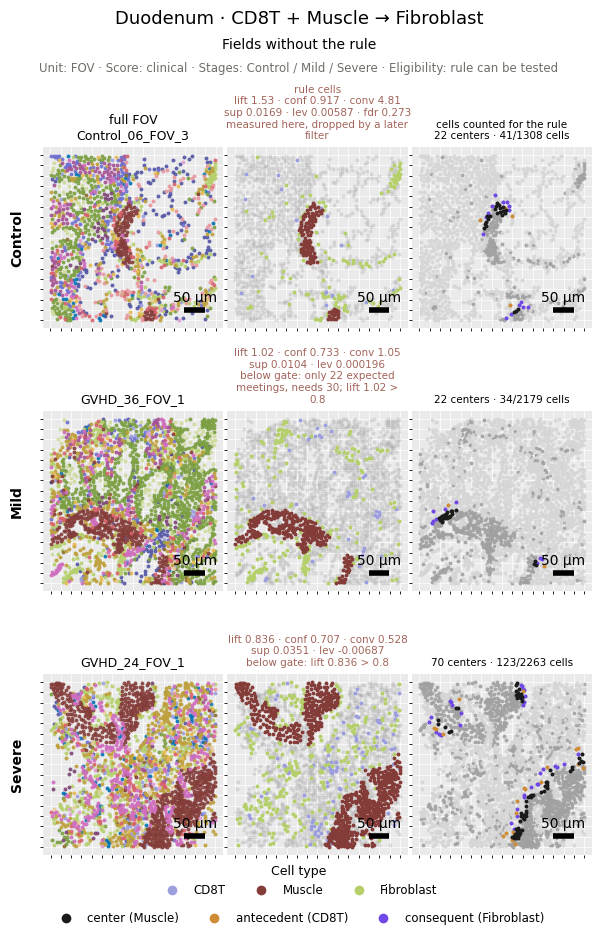

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_6eadd755c3_complex_fovs_avoidance.pdf


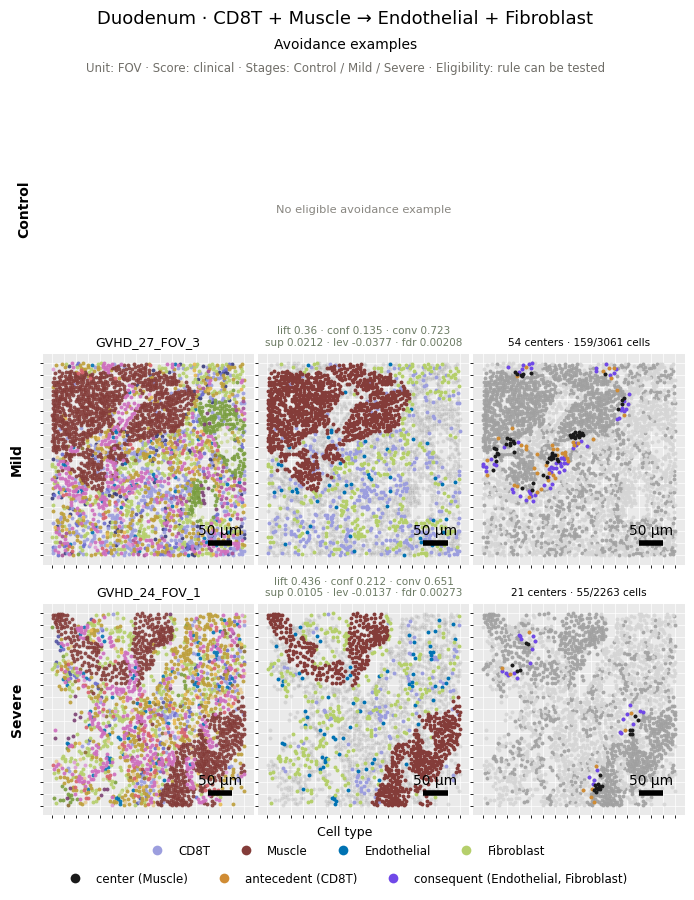

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Duodenum_6eadd755c3_complex_fovs_no_rule.pdf


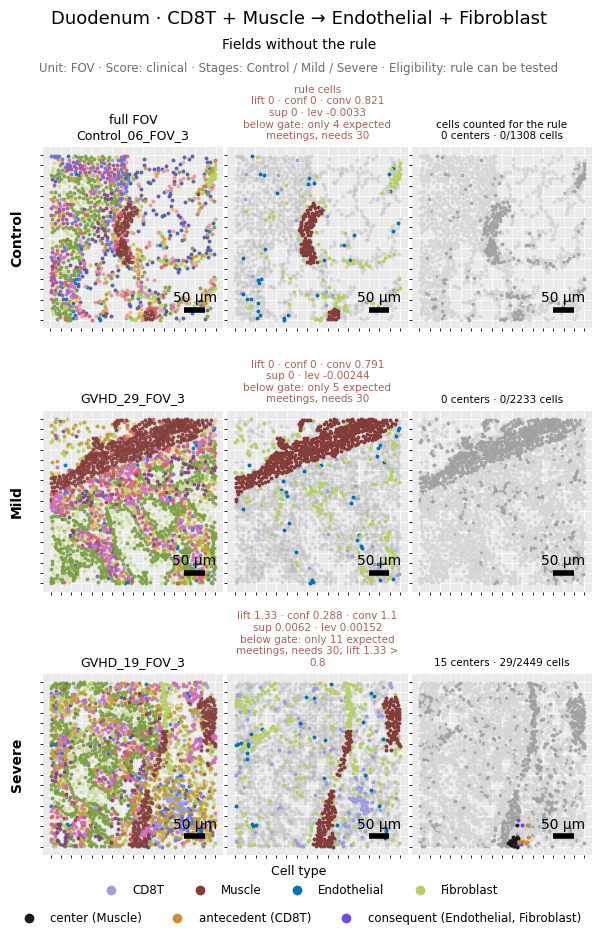

In [16]:
show_selected(10)

[11] Colon: CD4T -> Goblet  vs  CD4T + Epithelial + Fibroblast -> Goblet
FOVs testable for both rules; net = attraction share − avoidance share.


,stage,role,attraction,avoidance,eligible,patients,rule_patients,net
0,Control,parent,0,15,25,4,4,-0.600000
1,Control,complex,19,1,25,4,4,0.720000
2,Mild,parent,0,4,9,3,1,-0.444444
3,Mild,complex,7,0,9,3,3,0.777778
4,Severe,parent,1,12,39,12,6,-0.282051
5,Severe,complex,17,10,39,12,10,0.179487


saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_9be4bce9a2_summary.pdf


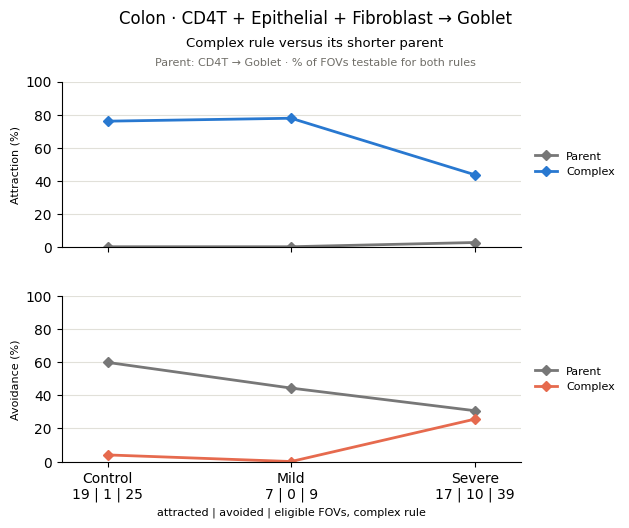

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_9be4bce9a2_parent_fovs_attraction.pdf


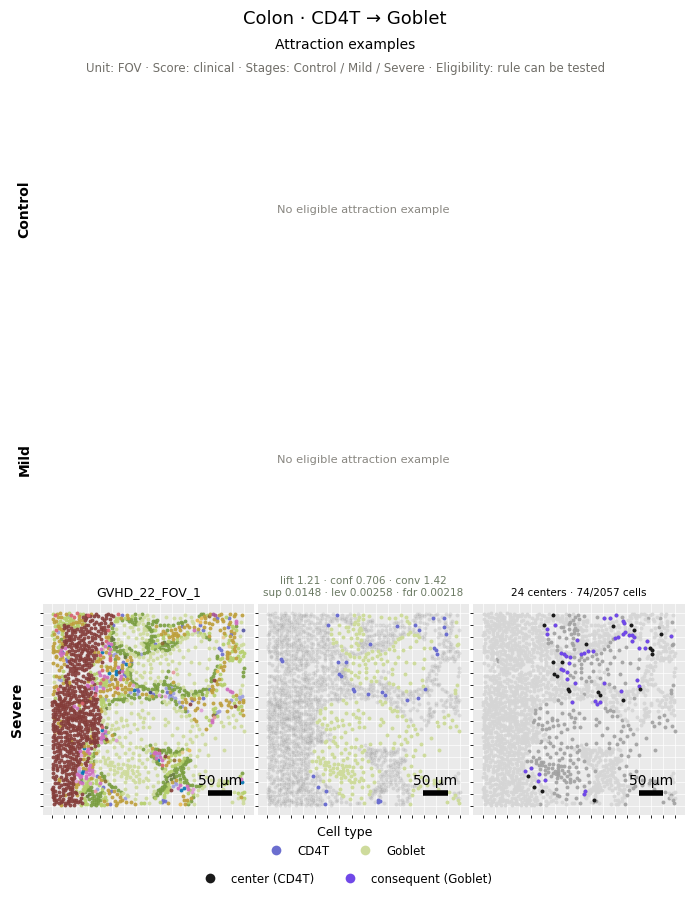

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_9be4bce9a2_parent_fovs_avoidance.pdf


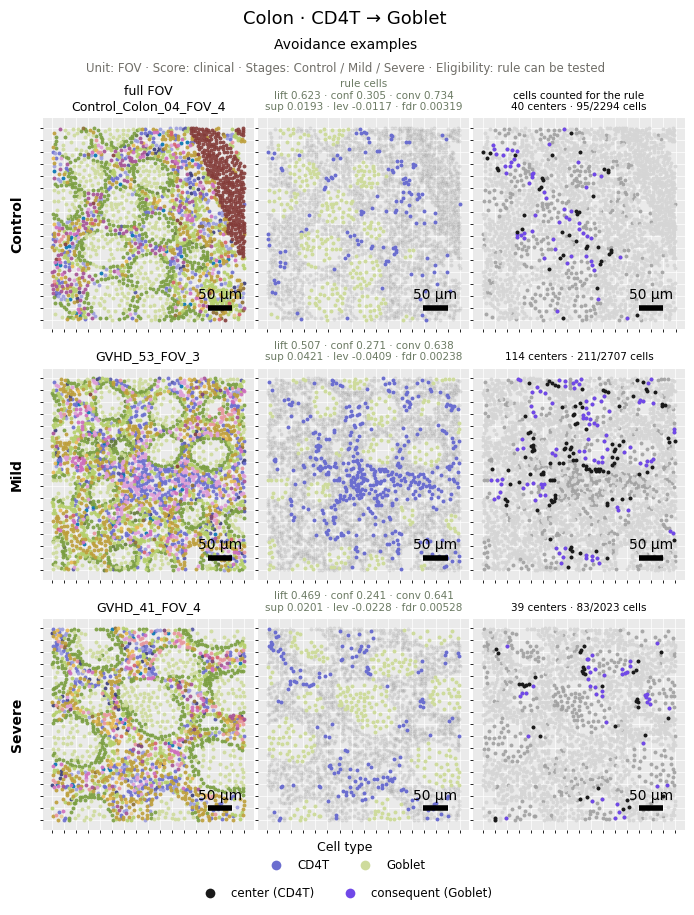

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_9be4bce9a2_parent_fovs_no_rule.pdf


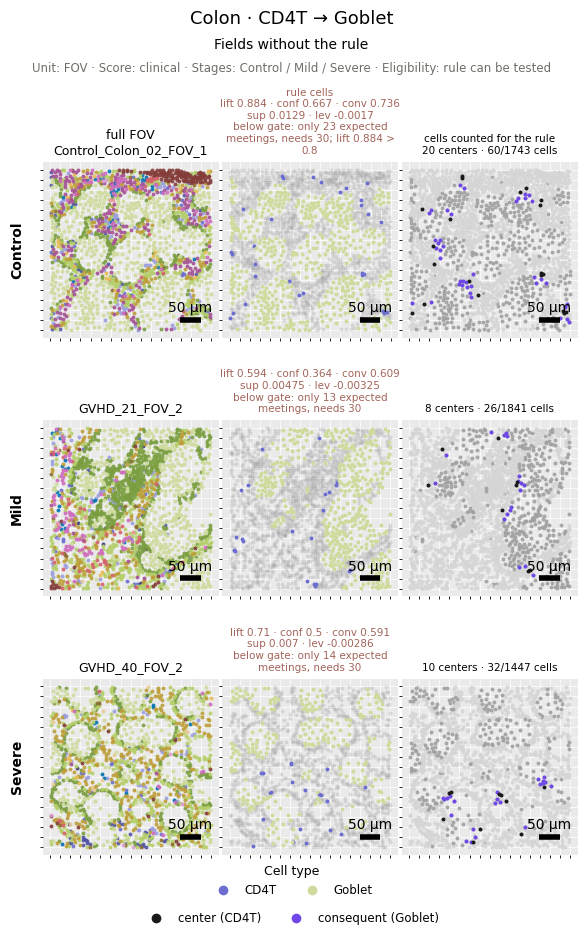

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_9be4bce9a2_complex_fovs_attraction.pdf


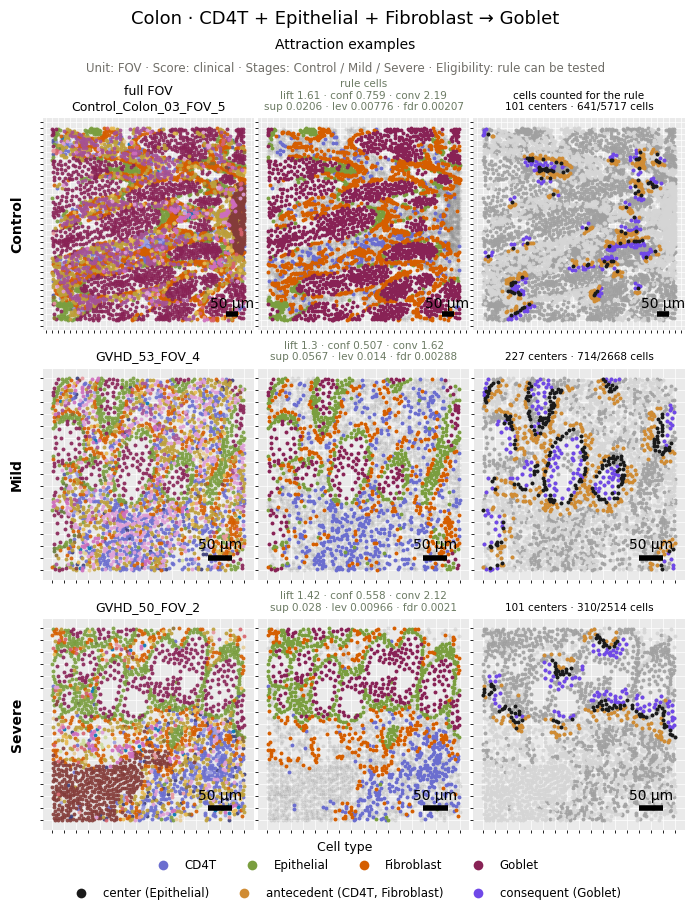

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_9be4bce9a2_complex_fovs_avoidance.pdf


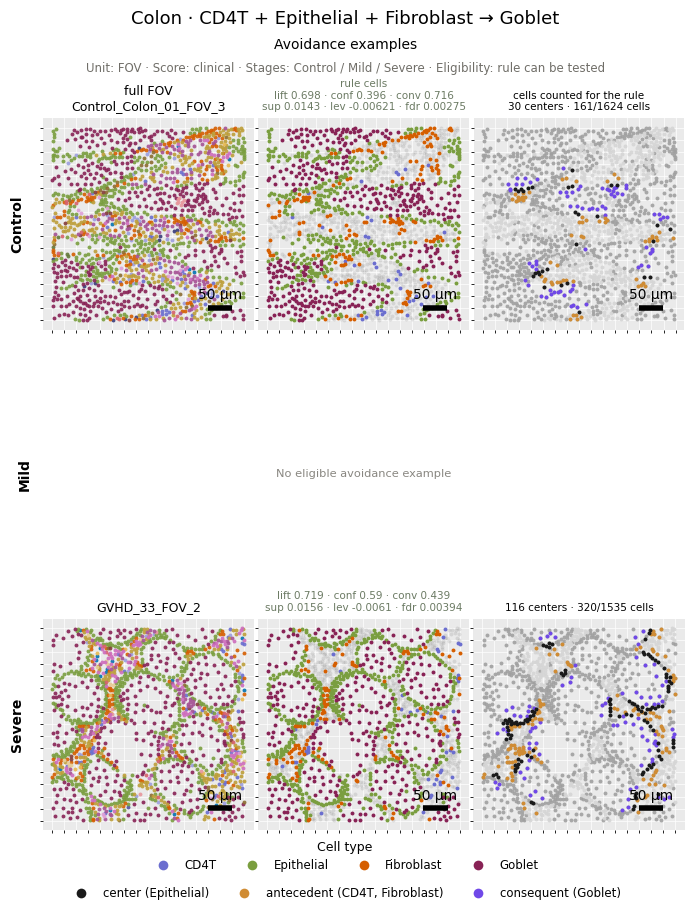

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_9be4bce9a2_complex_fovs_no_rule.pdf


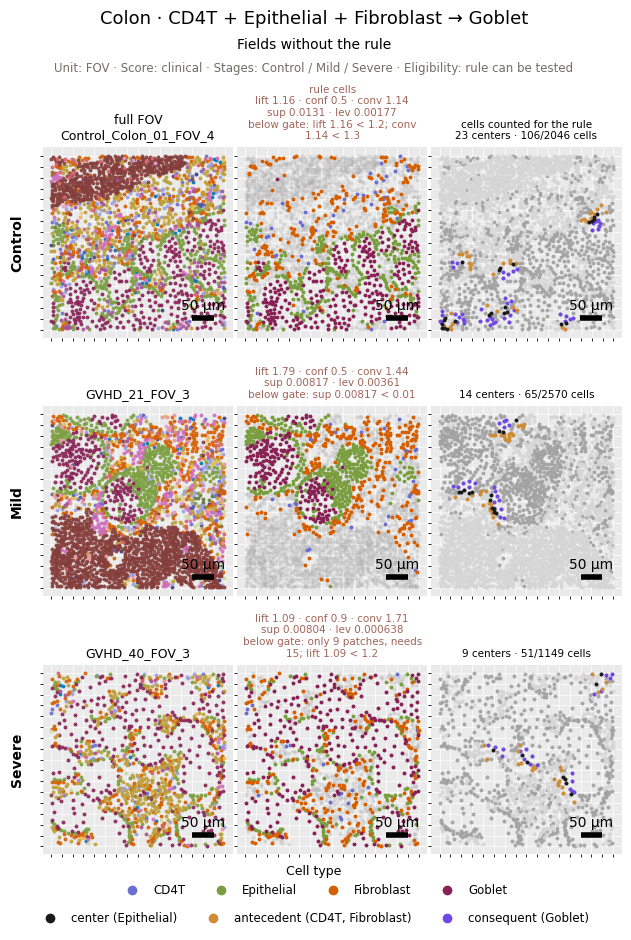

In [17]:
show_selected(11)

[12] Colon: CD4T -> Goblet  vs  CD4T + Epithelial -> Goblet
FOVs testable for both rules; net = attraction share − avoidance share.


,stage,role,attraction,avoidance,eligible,patients,rule_patients,net
0,Control,parent,0,15,25,4,4,-0.600000
1,Control,complex,21,0,25,4,4,0.840000
2,Mild,parent,0,4,9,3,1,-0.444444
3,Mild,complex,7,0,9,3,3,0.777778
4,Severe,parent,1,12,38,12,6,-0.289474
5,Severe,complex,22,3,38,12,10,0.500000


saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_1dd9fae822_summary.pdf


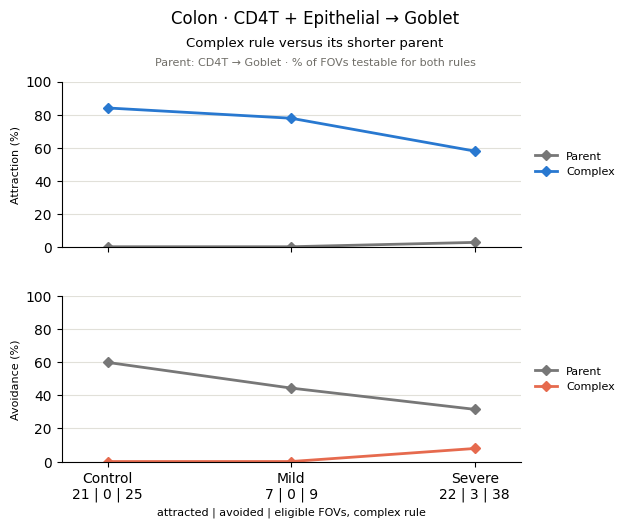

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_1dd9fae822_parent_fovs_attraction.pdf


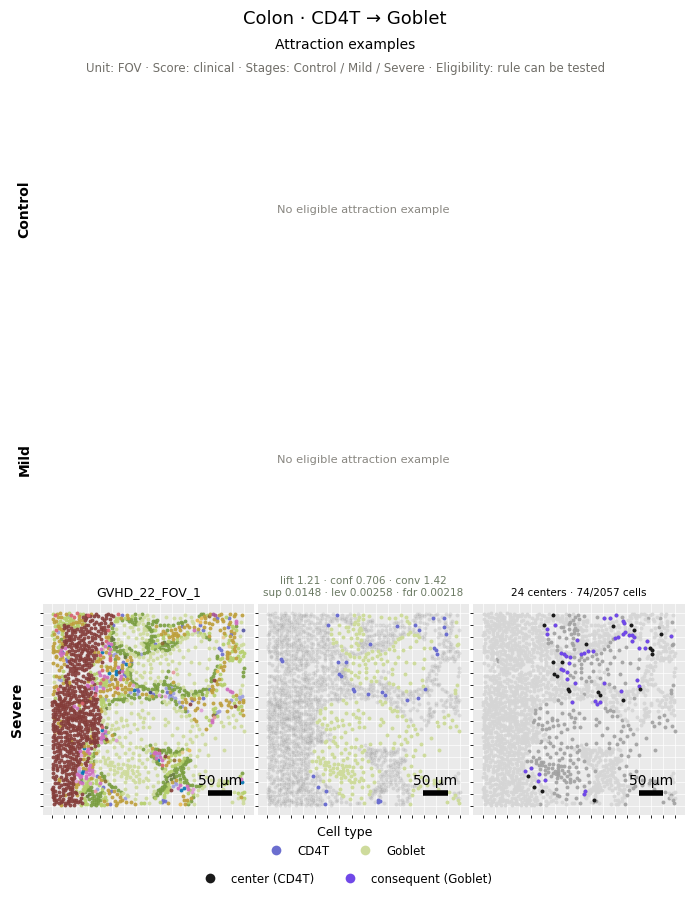

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_1dd9fae822_parent_fovs_avoidance.pdf


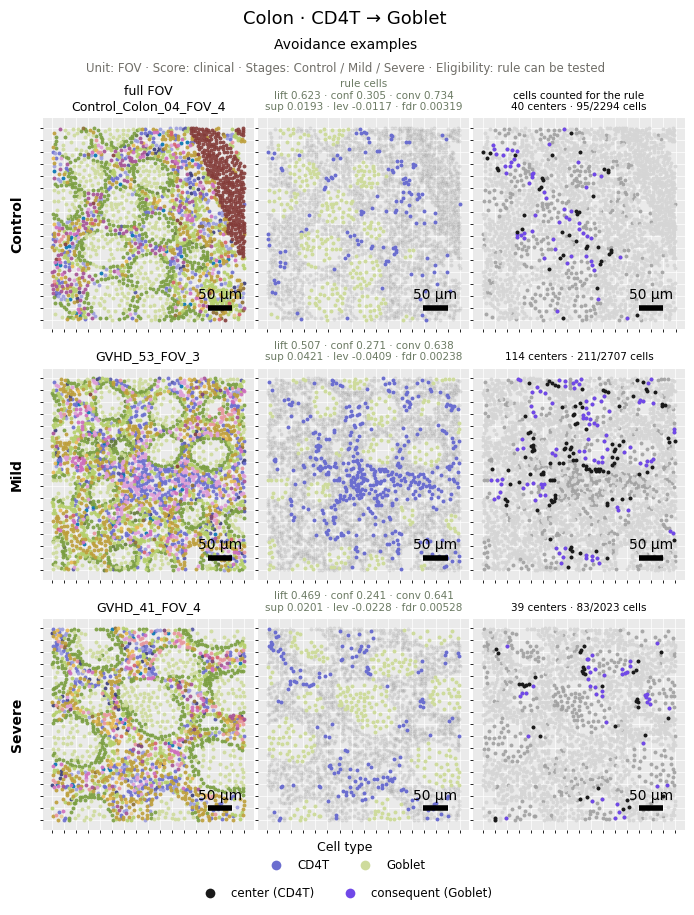

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_1dd9fae822_parent_fovs_no_rule.pdf


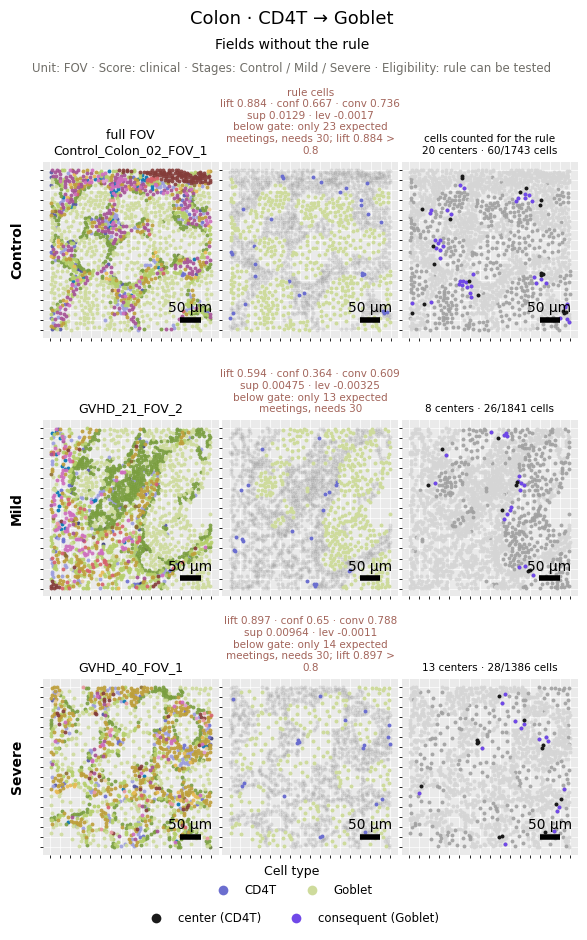

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_1dd9fae822_complex_fovs_attraction.pdf


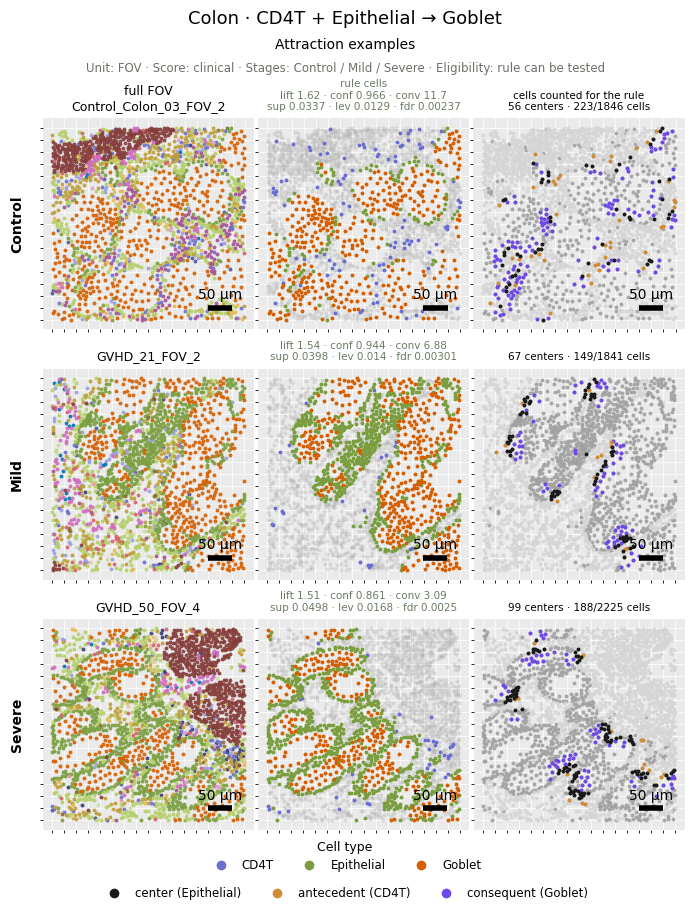

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_1dd9fae822_complex_fovs_avoidance.pdf


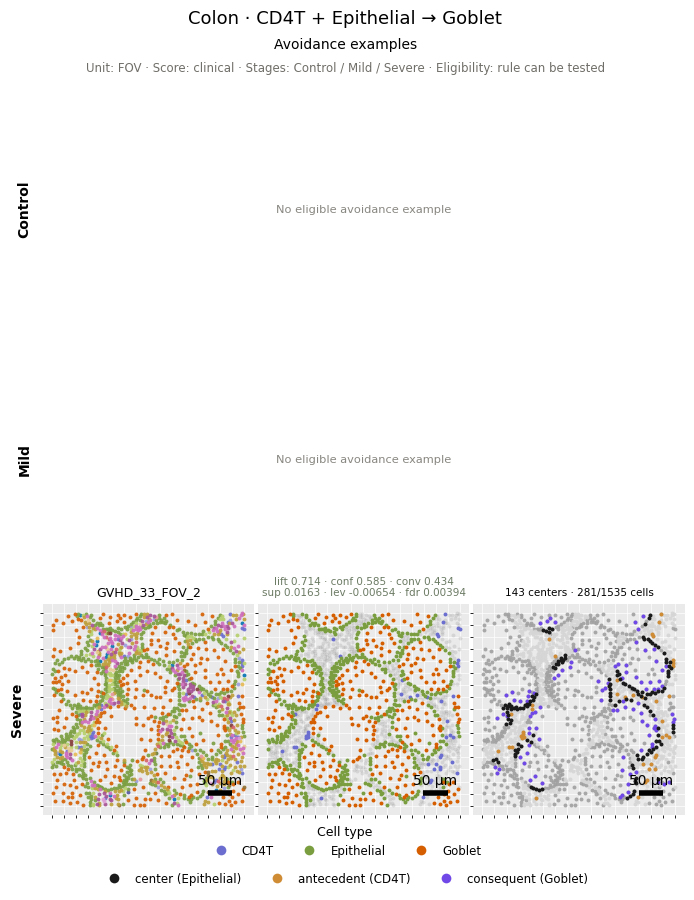

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_1dd9fae822_complex_fovs_no_rule.pdf


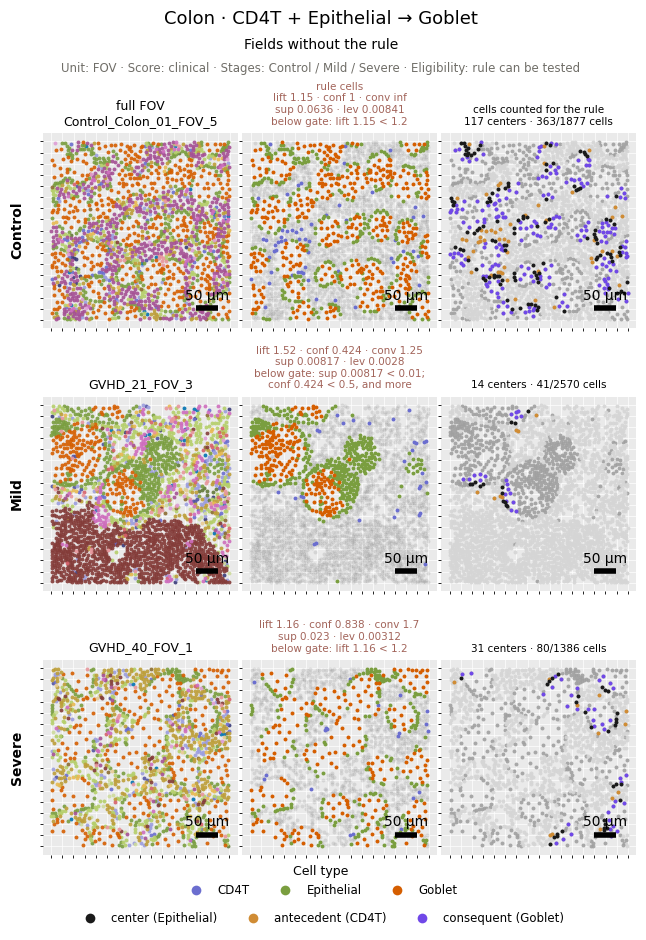

In [18]:
show_selected(12)

[13] Colon: Epithelial + Goblet -> Plasma  vs  Epithelial + Fibroblast + Goblet -> Plasma
FOVs testable for both rules; net = attraction share − avoidance share.


,stage,role,attraction,avoidance,eligible,patients,rule_patients,net
0,Control,parent,1,18,25,4,4,-0.680000
1,Control,complex,13,8,25,4,4,0.200000
2,Mild,parent,0,5,15,4,3,-0.333333
3,Mild,complex,0,3,15,4,2,-0.200000
4,Severe,parent,0,12,32,12,5,-0.375000
5,Severe,complex,2,6,32,12,4,-0.125000


saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_43f28130c6_summary.pdf


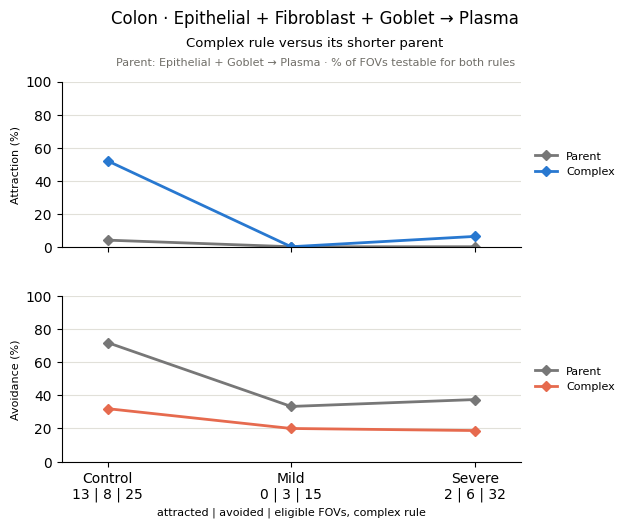

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_43f28130c6_parent_fovs_attraction.pdf


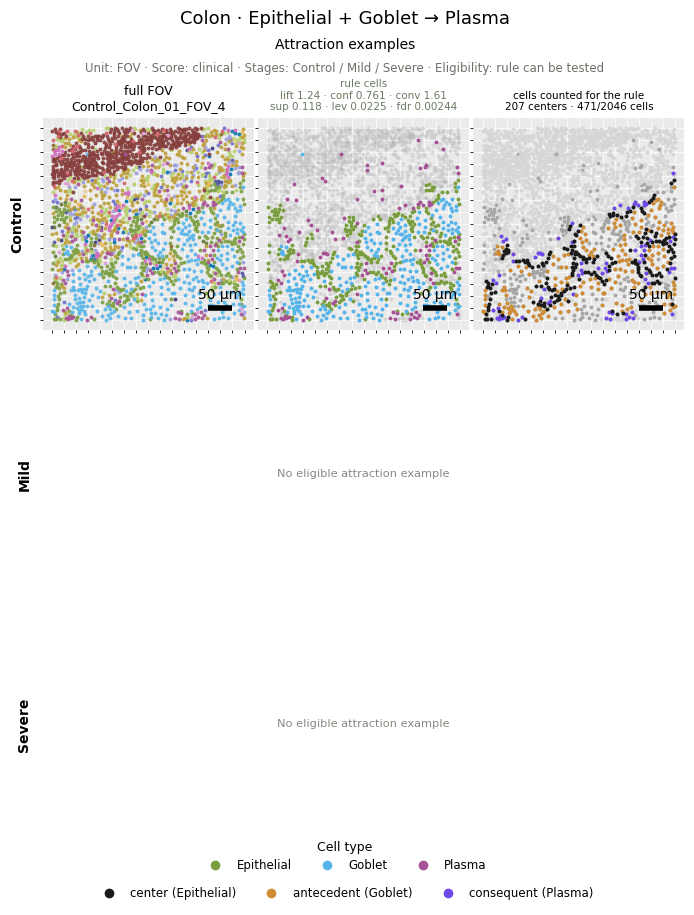

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_43f28130c6_parent_fovs_avoidance.pdf


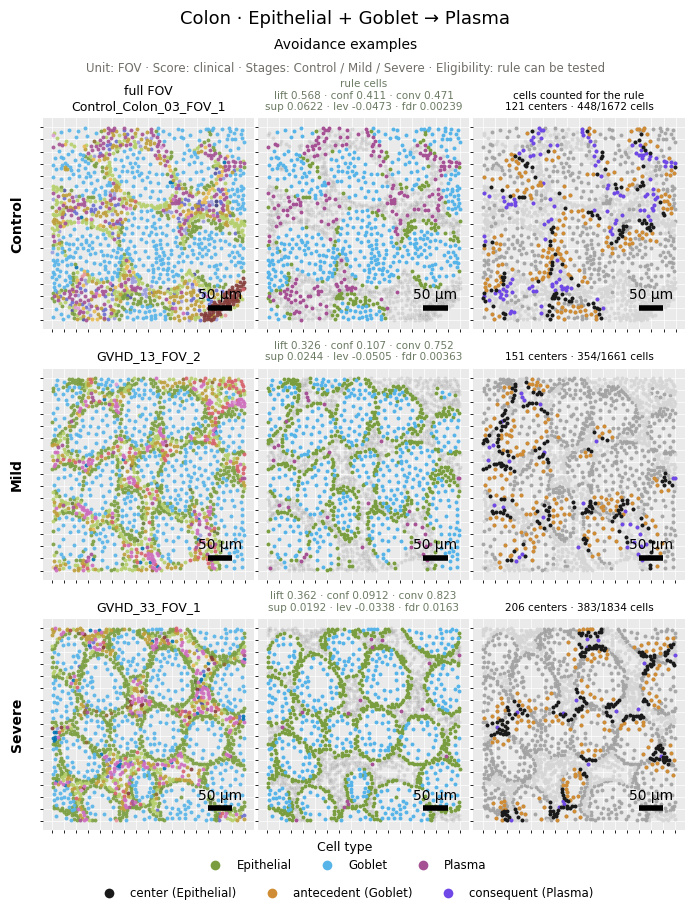

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_43f28130c6_parent_fovs_no_rule.pdf


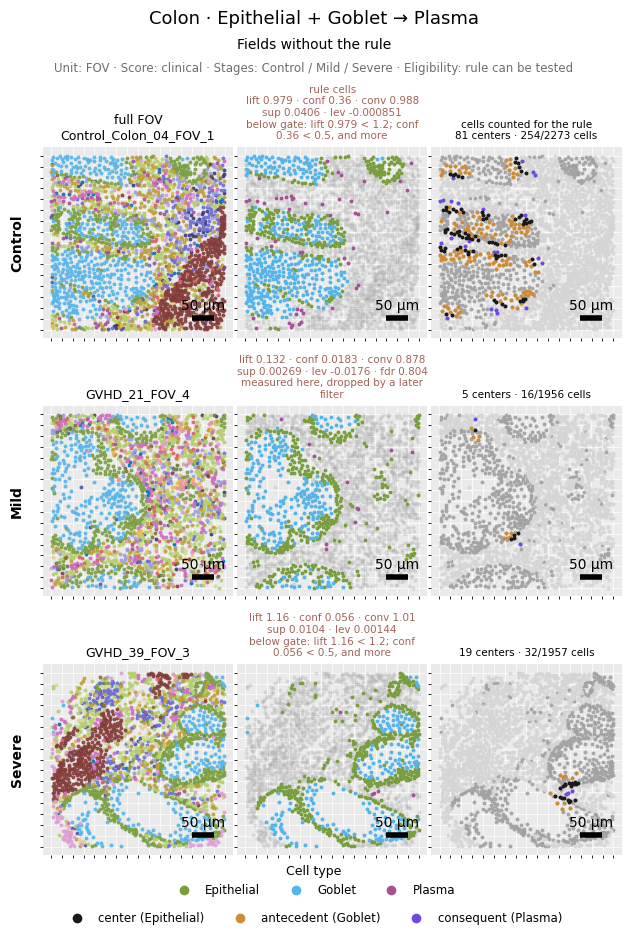

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_43f28130c6_complex_fovs_attraction.pdf


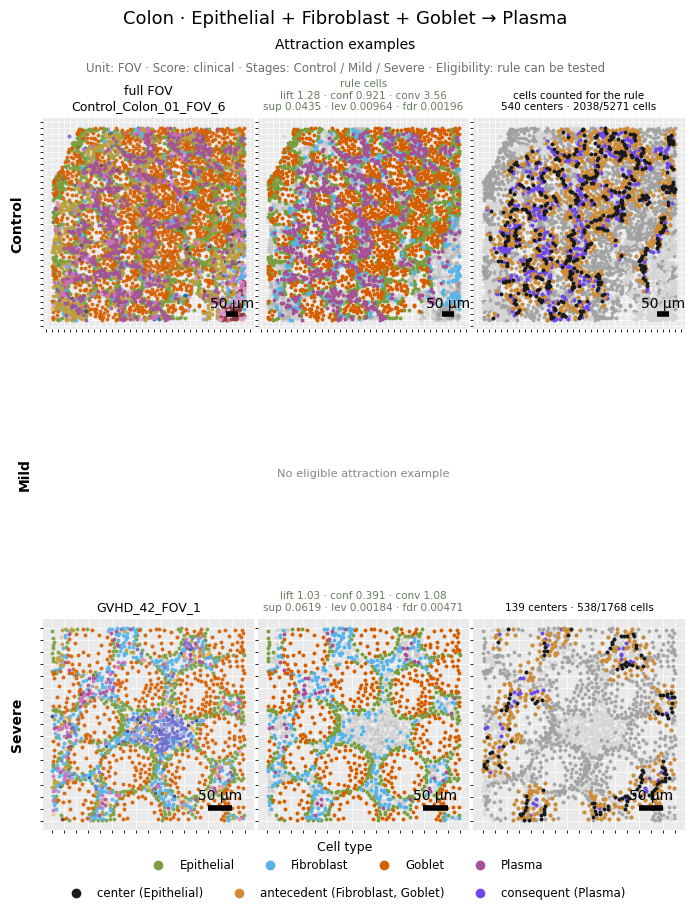

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_43f28130c6_complex_fovs_avoidance.pdf


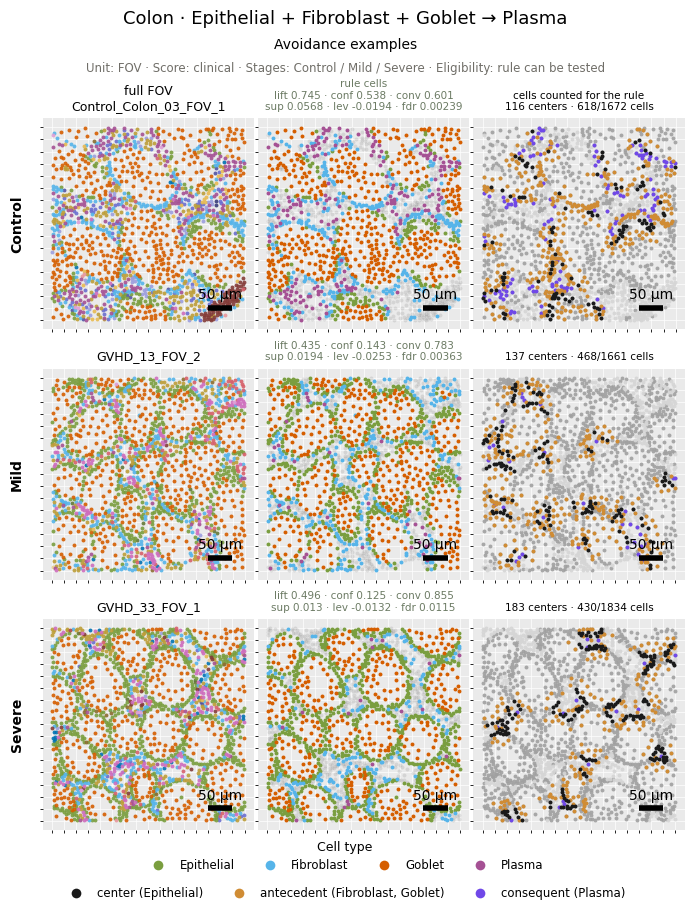

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\complex_rules\summary_downloads\reversal_Colon_43f28130c6_complex_fovs_no_rule.pdf


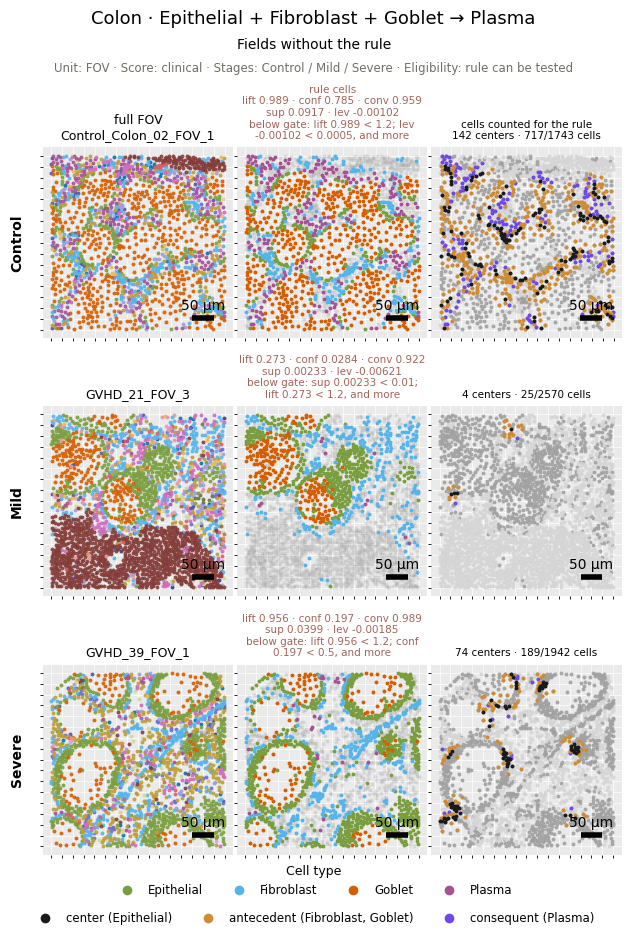

In [19]:
show_selected(13)